# Chili growth stages, weather stress and yield — Red Sky 86 F1

**Goal.** Use weather data to estimate when chili plants reach each growth stage, track rain and
weather stress, and estimate harvest yield and yield loss.

**Field.** Blocks A01–A04, transplanted 4–7 July 2026. Season window: 4 July to 12 October 2026.

**How to read this notebook.** Each step has a short explanation in plain words, then the code,
then a printed check (rows, date range, missing values). Every number that is an *assumption*
(not measured in the field) is set in the settings cell below and labelled as an assumption.

In [1]:
# Tools we use: pandas for tables, numpy for maths, matplotlib for charts
import csv, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Folders for saved results
os.makedirs("outputs/tables", exist_ok=True)
os.makedirs("outputs/charts", exist_ok=True)

# ---- Input files: change these paths to switch to another data file ----
QC_FILE        = "QA_QC-Management.csv"            # field QC sheet
WEATHER_FILE   = "POWER_Point_Hourly_20260704_20261012_012d14N_104d08E_LST.csv"       # NASA hourly weather at the site
SOIL_FILE      = "POWER_Point_Daily_Soil_20260704_20261012_012d14N_104d08E_LST.csv"   # NASA daily soil values at the site
WEATHER_FILE_OTHER_POINT = "POWER_Point_Hourly_20260407_20261112_012d00N_104d00E_LST.csv"   # first download, 12.0 N 104.0 E (comparison only)

# ---- Settings: every fixed number is here so it is easy to find and defend ----
SEASON_START = pd.Timestamp("2026-07-04")   # 0 DAT of block A01 (from the field sheet)
SEASON_END   = pd.Timestamp("2026-10-12")   # recorded harvest date for A01-A04 (from the field sheet)

# Base temperature for growing degree days. ASSUMPTION: common value for pepper, not in the project files.
TBASE       = 10.0   # main case
TBASE_CHECK = 15.0   # second case, to see how much the choice matters

# Flowering and fruit set (used in Step 4)
FLOWER_SPREAD_DAYS = 5         # ASSUMPTION: plants in a block do not all flower on one day; spread (std. dev.) in days
FLOWER_SPREAD_CHECK = [3, 7]   # ASSUMPTION: smaller and larger spread, to see how much it matters
FRUIT_LAG_DAYS = (7, 14)       # from the lecture slide: young fruits appear about 1-2 weeks after flowering
CYCLE_END_DAT = 150            # from the sheet title 'AGRONOMIC GROWTH STANDARD (0-150 DAT)'

# Yield (used in Step 5)
PLANTS_PER_BLOCK = 12500        # given: 1 block = 0.5 ha, 1 ha = 25,000 plants
YIELD_KG_BASE    = 1.5          # kg per plant, seed company planting guide (lower figure)
YIELD_KG_UPPER   = 1.6          # kg per plant, seed company planting guide (upper figure)
N_HARVESTS       = 5            # the sheet has columns for 5 harvests
# ASSUMPTIONS for yield loss: no project file gives these
LOSS_PER_HEAT_DAY       = 0.5   # % of yield lost for each heat day in the sensitive window
LOSS_PER_HEAVY_RAIN_DAY = 0.5   # % of yield lost for each heavy-rain day in the sensitive window
LOSS_PER_HUMID_DAY      = 0.25  # % of yield lost for each very-humid day in the sensitive window
LOSS_CAP                = 30.0  # % - the weather loss is never allowed above this
HUMID_DAY_HOURS         = 12    # a day with 12 or more very-humid hours counts as a very-humid day
SENSITIVE_DAT           = (40, 75)   # flowering and fruit set: just before half-flowering (Step 4) to first harvest

# Stress limits. ASSUMPTIONS: none of the project files give these numbers.
HEAT_C        = 32.0   # an hour at or above 32 C counts as a heat-stress hour
HEAVY_RAIN_MM = 7.6    # an hour with 7.6 mm or more counts as a heavy-rain hour
HEAVY_DAY_MM  = 20.0   # a day with 20 mm or more counts as a heavy-rain day
HUMID_RH      = 95.0   # an hour at or above 95 % humidity counts as a very-humid hour

# Chart colours (one fixed colour per thing we draw)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.edgecolor": "#c3c2b7",
                     "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11})

def check(df, name, date_col=None):
    # Short check we print after every load or cleaning step
    print(f"CHECK {name}: {len(df)} rows, {df.shape[1]} columns")
    if date_col:
        print(f"  dates: {df[date_col].min()}  to  {df[date_col].max()}")
    missing = df.isna().sum()
    missing = missing[missing > 0]
    if len(missing) == 0:
        print("  missing values: none")
    elif len(missing) <= 8:
        print("  missing values:", {k: int(v) for k, v in missing.items()})
    else:
        print(f"  missing values: {int(missing.sum())} empty cells in {len(missing)} columns")

def date_axis(ax):
    # Show dates on the x axis as '04 Jul'
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

# Step 1 — Inspect the data

## 1.1 Load the field QC sheet

The sheet `QA_QC-Management.csv` was exported from Excel. It is not a normal table:

* it uses the `latin1` text encoding,
* the column titles are spread over **three rows** (rows 4, 5 and 6): the stage, the thing measured,
  and the plant number.

So we read it as plain rows first, and build one clear column name from those three rows,
like `S3|Plant Height (cm)|P#1` (stage 3, plant height, plant 1).

In [2]:
# Read the sheet as plain rows of text
with open(QC_FILE, encoding="latin1", newline="") as f:
    raw = list(csv.reader(f))

n_cols = max(len(r) for r in raw)
raw = [r + [""] * (n_cols - len(r)) for r in raw]      # make every row the same length
print("rows in file:", len(raw), "| columns:", n_cols)

def tidy(text):
    # remove line breaks and extra spaces inside a header cell
    return " ".join(text.split())

# Build one name per column from header rows 4, 5 and 6
stage_row, param_row, plant_row = raw[3], raw[4], raw[5]
names, seen = [], {}
stage, param = "", ""
for j in range(n_cols):
    s, p, sub = tidy(stage_row[j]), tidy(param_row[j]), tidy(plant_row[j])
    if j < 4:                                   # first 4 columns: batch, zone, block, planting date
        name = s
    else:
        if s.startswith("Stage"):               # a new stage starts here, e.g. 'Stage 3_'
            stage = "S" + s.replace("Stage", "").replace("_", "").strip()
        elif s == "Other":                      # extra working columns at the far right
            stage = "X"
        if p:                                   # a new measurement starts here
            param = p
        name = f"{stage}|{param}|{sub}".rstrip("|")
    seen[name] = seen.get(name, 0) + 1          # make repeated names unique: name, name_2, ...
    names.append(name if seen[name] == 1 else f"{name}_{seen[name]}")

# Data rows start at row 7. Keep only rows that have a block code.
data = [[cell.strip() or None for cell in r] for r in raw[6:]]    # empty cells become 'missing'
sheet = pd.DataFrame(data, columns=names)
sheet = sheet[sheet["Block"].notna()].reset_index(drop=True).copy()

check(sheet, "field sheet (all blocks)")
print("example column names:", names[40], "|", names[125], "|", names[180])

rows in file: 129 | columns: 334
CHECK field sheet (all blocks): 113 rows, 334 columns
  missing values: 36568 empty cells in 333 columns
example column names: S3|Plant Height (cm)|P#1 | S4|Plant Flowering (%), and Flowers per Plant (No. flowers/plant)|P#1 | S6|Fruit Length (cm)|P#1


## 1.2 Which blocks have observations?

We count how many filled cells each block has after the planting date.

In [3]:
def to_date(col):
    # Dates are written day/month/year. Anything that is not a real date becomes 'missing'.
    return pd.to_datetime(col, dayfirst=True, format="mixed", errors="coerce")

extra = pd.DataFrame({"planting_date": to_date(sheet["Planting Date"]),
                      "filled_cells": sheet[names[4:]].notna().sum(axis=1)})
sheet = pd.concat([sheet, extra], axis=1)

print("blocks listed:", len(sheet))
print("blocks with a planting date:", sheet["planting_date"].notna().sum())
print("blocks with observations:", (sheet["filled_cells"] > 0).sum())

# Keep only the blocks that have observations
field = sheet[sheet["filled_cells"] > 0].reset_index(drop=True)
display(field[["Block", "planting_date", "filled_cells"]])

blocks listed: 113
blocks with a planting date: 98
blocks with observations: 4


,Block,planting_date,filled_cells
0,A01,2026-07-04,243
1,A02,2026-07-05,235
2,A03,2026-07-06,235
3,A04,2026-07-07,235


## 1.3 Bad dates in the pest/disease section

Some weekly pest/disease dates show the year **1900** (for example `16/03/1900`) or `#REF!`.
That is an Excel formula error, not a real date. We turn those cells into *missing*.
The weekly pest **counts** themselves are empty for all blocks, so there is no pest data to use.

In [4]:
pest_date_cols  = [c for c in names if c.startswith("S9|") and "|Date" in c]
pest_count_cols = [c for c in names if c.startswith("S9|") and "|W" in c]

pest_dates = field[pest_date_cols].apply(to_date)
bad = (pest_dates < "2026-01-01") | (field[pest_date_cols].notna() & pest_dates.isna())
print("pest date cells filled:", int(field[pest_date_cols].notna().sum().sum()))
print("  bad (year 1900 or #REF!):", int(bad.sum().sum()))
print("  good dates kept:", int((pest_dates >= "2026-01-01").sum().sum()))
print("pest COUNT cells filled:", int(field[pest_count_cols].notna().sum().sum()))

pest date cells filled: 47
  bad (year 1900 or #REF!): 19
  good dates kept: 28
pest COUNT cells filled: 0


## 1.4 Survey dates of each stage

For every block we take the date written at the start of each stage and count the days after
transplanting (DAT).

**Important:** the dates are exactly planting date + 0, 7, 30, 45, 60 and 75 days in all four
blocks. So they are **planned survey days**, not the day the plant really reached the stage.

In [5]:
stage_names = {1: "Transplant", 2: "Establishment", 3: "Vegetative",
               4: "Flowering", 5: "Fruit set", 6: "First harvest"}
rows = []
for _, r in field.iterrows():
    for n, label in stage_names.items():
        date_col = [c for c in names if c.startswith(f"S{n}|")][0]   # first column of the stage = its date
        d = to_date(pd.Series([r[date_col]]))[0]
        rows.append({"block": r["Block"], "planting_date": r["planting_date"], "stage_no": n,
                     "stage": label, "survey_date": d, "DAT": (d - r["planting_date"]).days})
surveys = pd.DataFrame(rows)
check(surveys, "survey dates", "survey_date")
display(surveys.pivot(index="block", columns="stage", values="DAT")[list(stage_names.values())])
surveys.to_csv("outputs/tables/survey_dates.csv", index=False)

CHECK survey dates: 24 rows, 6 columns
  dates: 2026-07-04 00:00:00  to  2026-09-20 00:00:00
  missing values: none


stage,Transplant,Establishment,Vegetative,Flowering,Fruit set,First harvest
block,,,,,,
A01,0,7,30,45,60,75
A02,0,7,30,45,60,75
A03,0,7,30,45,60,75
A04,0,7,30,45,60,75


## 1.5 One table per category (teacher's rule)

> "Please use this for AI data training. When using this, separate into categories for training,
> do not use the overall data."

So we do **not** make one big table. We make one small table per category.
Each table has **one row per plant per survey**: block, plant number, survey date, DAT and the value.
Later steps fit each category on its own.

In [6]:
# category name -> (start of the column name, stage number where it was measured)
category_cols = {
    "vigor":          ("S3|Plant Vigor Score", 3),
    "height":         ("S3|Plant Height", 3),
    "canopy_A":       ("S3|Canopy Diameter (cm) A", 3),
    "canopy_B":       ("S3|Canopy Diameter (cm) B", 3),
    "branching":      ("S3|Branching", 3),
    "flowers":        ("S4|Plant Flowering", 4),
    "young_fruits":   ("S5|Young/Developing Fruits", 5),
    "fruit_length":   ("S6|Fruit Length", 6),
    "fruit_diameter": ("S6|Fruit Diameter", 6),
}

def long_table(prefix, stage_no, value_name):
    # Turn the 20 plant columns of one category into rows: one row per plant
    cols = [c for c in names if c.startswith(prefix) and c.count("|") == 2]
    out = []
    for _, r in field.iterrows():
        s = surveys[(surveys.block == r["Block"]) & (surveys.stage_no == stage_no)].iloc[0]
        for plant_no, c in enumerate(cols, start=1):
            out.append({"block": r["Block"], "plant_no": plant_no, "survey_date": s.survey_date,
                        "DAT": s.DAT, value_name: pd.to_numeric(r[c], errors="coerce")})
    return pd.DataFrame(out)

cat = {name: long_table(prefix, n, name) for name, (prefix, n) in category_cols.items()}

# Canopy diameter has two directions (A and B). Put them in one table and add their average.
canopy = cat.pop("canopy_A").merge(cat.pop("canopy_B"), on=["block", "plant_no", "survey_date", "DAT"])
canopy["canopy_mean"] = canopy[["canopy_A", "canopy_B"]].mean(axis=1)
cat["canopy"] = canopy

summary = []
for name, t in cat.items():
    t.to_csv(f"outputs/tables/category_{name}.csv", index=False)
    value = t.columns[-1]
    summary.append({"category": name, "rows": len(t), "DAT": t.DAT.iloc[0], "missing": int(t[value].isna().sum()),
                    "mean": round(t[value].mean(), 2), "min": t[value].min(), "max": t[value].max()})
display(pd.DataFrame(summary))

,category,rows,DAT,missing,mean,min,max
0,vigor,80,30,0,3.71,2.00,5.0
1,height,80,30,0,32.83,11.30,57.0
2,branching,80,30,0,4.38,1.00,12.0
3,flowers,80,45,0,1.79,0.00,9.0
4,young_fruits,80,60,0,35.00,7.00,77.0
5,fruit_length,80,75,0,6.19,4.30,7.3
6,fruit_diameter,80,75,0,0.86,0.60,1.0
7,canopy,80,30,0,15.72,7.35,28.5


**What this shows.** Every category has 80 rows (4 blocks × 20 plants) and no missing values.
Each category was measured at **one survey only**, so we have a snapshot per plant, not a growth
curve over time.

## 1.6 Stages and reference numbers found in the files

| Stage | Name | Timing in the sheet | Data present? |
|---|---|---|---|
| 1 | Transplant | 0 DAT | yes |
| 2 | Establishment | 7 DAT | yes |
| 3 | Vegetative | 30 DAT | yes |
| 4 | Flowering | 45 DAT | yes (flower abortion empty) |
| 5 | Fruit set | 60 DAT | yes |
| 6 | First harvest | 75 DAT | fruit length and diameter only |
| 7 | Maturity | 75 DAT+ | empty |
| 8 | Harvest | 75–150 DAT | empty |
| 9 | Plant health | 75–150 DAT | dates only, no counts |
| 10 | End of cycle | not given | empty |

| Reference number | Value | Source |
|---|---|---|
| Days to harvest | 75 days after transplanting | seed company planting guide |
| Transplant age | 4–5 leaves | planting guide and QC guideline |
| Fruit size | 6.5–7.8 cm long, 1.1–1.2 cm wide | planting guide |
| Yield | 1.5–1.6 kg per plant | planting guide |
| Fruit-tip rot risk | 75–80 days after planting | planting guide |
| GDD formula | GDD = max(0, Tmean − Tbase) | lecture slides (W1) |
| Base temperature | 10 °C (15 °C as a second check) | **assumption** – not in any file |
| GDD needed per stage | none given | must be calibrated from our own data |

# Step 2 — Clean the weather and make a daily table

## 2.1 Load the hourly weather

The file comes from NASA POWER for the field's own position (12.14 N, 104.08 E, local time). It has one row per hour with
air temperature `T2M` (°C), humidity `RH2M` (%) and rain `PRECTOTCORR` (mm in that hour).
The first lines are a text header, so we skip down to the line after `-END HEADER-`.

In [7]:
weather_file = WEATHER_FILE
with open(weather_file) as f:
    lines = f.read().splitlines()
header_end = lines.index("-END HEADER-")
print("file:", weather_file)
print("\n".join(lines[1:header_end]))            # show NASA's own description of the file

hourly = pd.read_csv(weather_file, skiprows=header_end + 1)
# Build one real date-time from the YEAR, MO (month), DY (day), HR (hour) columns
hourly["datetime"] = pd.to_datetime(dict(year=hourly.YEAR, month=hourly.MO, day=hourly.DY, hour=hourly.HR))
hourly = hourly[["datetime", "T2M", "RH2M", "PRECTOTCORR"]]

check(hourly, "hourly weather (raw)", "datetime")
print("  repeated hours:", hourly.datetime.duplicated().sum())
print("  hours with the missing code -999:", int((hourly.T2M == -999).sum()))

file: POWER_Point_Hourly_20260704_20261012_012d14N_104d08E_LST.csv
NASA/POWER Source Native Resolution Hourly Data 
Dates (month/day/year): 07/04/2026 through 10/12/2026 in LST
Location: Latitude  12.14   Longitude 104.08 
Elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = 121.88 meters
The value for missing source data that cannot be computed or is outside of the sources availability range: -999 
Parameter(s): 
T2M             MERRA-2 Temperature at 2 Meters (C) 
RH2M            MERRA-2 Relative Humidity at 2 Meters (%) 
PRECTOTCORR     MERRA-2 Precipitation Corrected (mm/hour) 
CHECK hourly weather (raw): 2424 rows, 4 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 23:00:00
  missing values: none
  repeated hours: 0
  hours with the missing code -999: 0


## 2.2 Clean it

Three cleaning rules:

1. NASA writes **-999** when it has no value. We turn that into *missing*.
2. Values that cannot be real are flagged: temperature outside 0–50 °C, humidity outside 0–100 %,
   rain below 0 or above 100 mm in one hour. (These limits are our own safety limits.)
3. We keep only the season, **4 July to 12 October 2026**. (NASA's download page reads dates as
   month/day/year, so 4 July must be typed as `07/04/2026`. A first download typed as `04/07` started on 7 April.)

In [8]:
# Rule 1: missing code -> missing
hourly = hourly.replace(-999, np.nan)

# Rule 2: flag impossible values
limits = {"T2M": (0, 50), "RH2M": (0, 100), "PRECTOTCORR": (0, 100)}
hourly["impossible"] = False
for col, (low, high) in limits.items():
    hourly["impossible"] |= (hourly[col] < low) | (hourly[col] > high)

print("Impossible rows found in the whole file:", int(hourly.impossible.sum()))
if hourly.impossible.any():
    display(hourly[hourly.impossible])
print("Hours with no value in the whole file:", int(hourly.T2M.isna().sum()))

# Rule 3: keep only the season and drop any impossible rows inside it
in_season = (hourly.datetime >= SEASON_START) & (hourly.datetime < SEASON_END + pd.Timedelta(days=1))
season = hourly[in_season & ~hourly.impossible].drop(columns="impossible").reset_index(drop=True)

check(season, "hourly weather (clean, season only)", "datetime")
days = (SEASON_END - SEASON_START).days + 1
print(f"  expected {days} days x 24 hours = {days * 24} rows")

Impossible rows found in the whole file: 0
Hours with no value in the whole file: 0
CHECK hourly weather (clean, season only): 2424 rows, 4 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 23:00:00
  missing values: none
  expected 101 days x 24 hours = 2424 rows


**What this shows.** This file has no impossible values and no missing hours: every hour of the
season is present. (The first download, checked in section 2.4, did contain a glitch: seven hours of
`990.01 mm` rain on 2 July, before planting.)

## 2.3 Daily table and stress hours

For each day we take the 24 hourly values and compute:

* `Tmax`, `Tmin` – hottest and coolest hour
* `Tmean` – average of the 24 hours; `Tmid` – (Tmax + Tmin) / 2, the form used in the lecture's GDD example
* `RH_mean` – average humidity; `rain_mm` – total rain
* `heat_hours` – hours at 32 °C or more
* `heavy_rain_hours` – hours with 7.6 mm or more
* `humid_hours` – hours at 95 % humidity or more
* `heavy_rain_day` – True if the day's rain is 20 mm or more

The hour counts use the **hourly** data on purpose: a daily average can hide a short stress event.

In [9]:
season["date"] = season.datetime.dt.normalize()
season["is_heat"]  = season.T2M >= HEAT_C
season["is_heavy"] = season.PRECTOTCORR >= HEAVY_RAIN_MM
season["is_humid"] = season.RH2M >= HUMID_RH

daily = season.groupby("date").agg(
    hours=("T2M", "count"),
    Tmax=("T2M", "max"), Tmin=("T2M", "min"), Tmean=("T2M", "mean"),
    RH_mean=("RH2M", "mean"), rain_mm=("PRECTOTCORR", "sum"),
    heat_hours=("is_heat", "sum"), heavy_rain_hours=("is_heavy", "sum"), humid_hours=("is_humid", "sum"),
).reset_index()
daily["Tmid"] = (daily.Tmax + daily.Tmin) / 2
daily["heavy_rain_day"] = daily.rain_mm >= HEAVY_DAY_MM
daily = daily.round(2)

check(daily, "daily weather", "date")
print("  days with fewer than 24 hours:", int((daily.hours < 24).sum()))
display(daily[["Tmax", "Tmin", "Tmean", "Tmid", "RH_mean", "rain_mm"]].describe().round(2).loc[["mean", "min", "max"]])

print("Season totals")
print("  total rain:", round(daily.rain_mm.sum(), 1), "mm")
print("  hottest hour:", season.T2M.max(), "C")
print(f"  heat-stress hours (>= {HEAT_C} C):", int(daily.heat_hours.sum()))
print(f"  heavy-rain hours (>= {HEAVY_RAIN_MM} mm):", int(daily.heavy_rain_hours.sum()))
print(f"  heavy-rain days (>= {HEAVY_DAY_MM} mm):", int(daily.heavy_rain_day.sum()), "of", len(daily))
print(f"  very-humid hours (>= {HUMID_RH} %):", int(daily.humid_hours.sum()), "of", len(season))
if season.is_heavy.any():                       # list the heavy-rain hours, if there are any
    display(season[season.is_heavy][["datetime", "T2M", "RH2M", "PRECTOTCORR"]])

CHECK daily weather: 101 rows, 12 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 00:00:00
  missing values: none
  days with fewer than 24 hours: 0


,Tmax,Tmin,Tmean,Tmid,RH_mean,rain_mm
mean,31.56,24.18,27.44,27.87,83.37,7.39
min,27.59,22.05,25.52,25.76,70.22,0.05
max,35.42,25.30,29.38,29.58,93.89,42.94


Season totals
  total rain: 746.5 mm
  hottest hour: 35.42 C
  heat-stress hours (>= 32.0 C): 171
  heavy-rain hours (>= 7.6 mm): 0
  heavy-rain days (>= 20.0 mm): 7 of 101
  very-humid hours (>= 95.0 %): 544 of 2424


## 2.4 Check: does the grid square matter?

NASA POWER does not measure at a point. It gives the average of a **grid square** about 50 km wide.
The first download for this project used the round position 12.0 N, 104.0 E. The field is at
12.14 N, 104.08 E, only about 18 km away, but that falls in the **next grid square**
(the file headers below show a different average ground height for each).
Here we load the first download, clean it the same way, and compare the two for the same season.

In [10]:
def weather_figures(h):
    # the key season figures of one hourly weather table
    day = h.groupby(h.datetime.dt.normalize()).agg(
        Tmax=("T2M", "max"), Tmin=("T2M", "min"), rain=("PRECTOTCORR", "sum"),
        heat_hours=("T2M", lambda t: (t >= HEAT_C).sum()), humid_hours=("RH2M", lambda r: (r >= HUMID_RH).sum()))
    return {"mean Tmax (C)": day.Tmax.mean(), "hottest hour (C)": h.T2M.max(), "mean Tmin (C)": day.Tmin.mean(),
            "mean humidity (%)": h.RH2M.mean(), "total rain (mm)": day.rain.sum(),
            "heat-stress hours": day.heat_hours.sum(), "heat days": (day.heat_hours > 0).sum(),
            "heavy-rain days": (day.rain >= HEAVY_DAY_MM).sum(),
            "very-humid hours": day.humid_hours.sum(), "very-humid days": (day.humid_hours >= HUMID_DAY_HOURS).sum(),
            "GDD per day (base 10)": ((day.Tmax + day.Tmin) / 2 - TBASE).clip(lower=0).mean()}

if os.path.exists(WEATHER_FILE_OTHER_POINT):
    with open(WEATHER_FILE_OTHER_POINT) as f:
        other_lines = f.read().splitlines()
    for line in other_lines[3:5]:                            # position and height of the other grid square
        print(line)
    other = pd.read_csv(WEATHER_FILE_OTHER_POINT, skiprows=other_lines.index("-END HEADER-") + 1).replace(-999, np.nan)
    other["datetime"] = pd.to_datetime(dict(year=other.YEAR, month=other.MO, day=other.DY, hour=other.HR))
    glitch = other[other.PRECTOTCORR > limits["PRECTOTCORR"][1]]
    print("impossible rain values in the first download:", len(glitch), "hours, on", sorted(set(glitch.datetime.dt.date.astype(str))))
    other = other[(other.datetime >= SEASON_START) & (other.datetime < SEASON_END + pd.Timedelta(days=1))]
    check(other[["datetime", "T2M", "RH2M", "PRECTOTCORR"]], "first download, season only", "datetime")

    grid_check = pd.DataFrame({"field square 12.14N 104.08E (used)": weather_figures(season),
                               "next square 12.0N 104.0E": weather_figures(other)}).round(1)
    display(grid_check)
    grid_check.to_csv("outputs/tables/grid_square_check.csv")
else:
    print("First download not in the folder - comparison skipped.")

Location: Latitude  12.0   Longitude 104.0 
Elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = 396.84 meters
impossible rain values in the first download: 7 hours, on ['2026-07-02']
CHECK first download, season only: 2424 rows, 4 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 23:00:00
  missing values: none


,field square 12.14N 104.08E (used),next square 12.0N 104.0E
mean Tmax (C),31.6,28.4
hottest hour (C),35.4,31.3
mean Tmin (C),24.2,22.6
mean humidity (%),83.4,89.7
total rain (mm),746.5,1291.6
heat-stress hours,171.0,0.0
heat days,41.0,0.0
heavy-rain days,7.0,19.0
very-humid hours,544.0,1187.0
very-humid days,4.0,65.0


**What this shows.** The two squares are neighbours, but they are not alike. The first download's
square has an average ground height of 397 m (it includes hills); the field's square averages 122 m.
The field's square is about 3 °C hotter by day, less humid, and has a little over half the rain.

This changes the story of the season: with the first download there was **no heat stress and a
lot of humidity stress**; with the field's own square there are **41 heat days and almost no
very-humid days**. We use the field's square for everything that follows, because it is the one the
field is in. The lesson for the limits section: the weather input is the largest uncertainty in
this project, and only a station in the field would settle it.

## 2.5 Soil values

**Is `soil_data_set.csv` from our field?** We look at its columns and dates.

In [11]:
soil_file = pd.read_csv("soil_data_set.csv", encoding="latin1")
check(soil_file, "soil_data_set.csv")
print("  columns:", list(soil_file.columns))
print("  time span:", soil_file.created_at.min(), "to", soil_file.created_at.max())
has_place = [c for c in soil_file.columns if any(k in c.lower() for k in ["lat", "lon", "region", "province", "site"])]
print("  location columns:", has_place if has_place else "none")
print("  soil pH range:", soil_file["Soil ph"].min(), "to", soil_file["Soil ph"].max())

CHECK soil_data_set.csv: 100 rows, 7 columns
  missing values: {'Notifi': 49}
  columns: ['created_at', 'entry_id', 'Soil Moistute(%)', 'Ambient Temperature©', 'Soil ph', 'Fuzzy Values', 'Notifi']
  time span: 2020-01-06 01:10:02 UTC to 2020-01-06 02:54:07 UTC
  location columns: none
  soil pH range: -7.19592 to 11.16265


**Decision: do not use it as site data.** The file has no latitude, longitude or region, it covers
less than two hours on 6 January 2020, and its pH readings include values that cannot be real
(below 0 and above 11). It is kept only as a general example of sensor data.

**What we use instead.** NASA POWER daily soil values for the same point and season:

* `GWETTOP` – wetness of the top soil layer (0 = dry, 1 = fully wet)
* `GWETROOT` – wetness of the root zone
* `GWETPROF` – wetness of the whole soil profile
* `TS` – temperature of the ground surface (°C)

These are **model estimates for a large grid square**, not sensor readings in our blocks.

In [12]:
soil_nasa_file = SOIL_FILE
with open(soil_nasa_file) as f:
    soil_lines = f.read().splitlines()
soil = pd.read_csv(soil_nasa_file, skiprows=soil_lines.index("-END HEADER-") + 1).replace(-999, np.nan)
# NASA gives the year and the day number in the year (DOY). Turn that into a date.
soil["date"] = pd.to_datetime(soil.YEAR.astype(str) + "-" + soil.DOY.astype(str), format="%Y-%j")
soil = soil[["date", "GWETTOP", "GWETROOT", "GWETPROF", "TS"]]
check(soil, "NASA daily soil", "date")

# Add the soil columns to the daily weather table (match on the date)
daily = daily.merge(soil, on="date", how="left")
check(daily, "daily weather + soil", "date")
daily.to_csv("outputs/tables/daily_weather.csv", index=False)
display(daily.head())

CHECK NASA daily soil: 101 rows, 5 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 00:00:00
  missing values: none
CHECK daily weather + soil: 101 rows, 16 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 00:00:00
  missing values: none


,date,hours,Tmax,Tmin,Tmean,RH_mean,rain_mm,heat_hours,heavy_rain_hours,humid_hours,Tmid,heavy_rain_day,GWETTOP,GWETROOT,GWETPROF,TS
0,2026-07-04,24,29.95,24.60,26.73,87.12,17.09,0,0,11,27.28,False,0.59,0.56,0.54,26.86
1,2026-07-05,24,32.99,23.66,27.92,80.59,6.67,5,0,7,28.33,False,0.59,0.58,0.56,28.51
2,2026-07-06,24,34.12,24.00,28.75,76.44,6.13,6,0,3,29.06,False,0.57,0.58,0.56,29.38
3,2026-07-07,24,31.35,25.08,27.47,83.58,34.75,0,0,4,28.22,True,0.66,0.60,0.58,27.73
4,2026-07-08,24,33.01,24.28,27.88,78.82,3.62,4,0,1,28.64,False,0.64,0.64,0.61,28.18


**Soil laboratory report (`DSSA.pdf`).** This is a scanned page, so the values below were typed in
by hand. The samples were taken on 9 March 2023 from fields labelled A1 and A2. They describe the
soil in general; they are **background, not season data**, and are not used in any calculation.

In [13]:
lab = pd.DataFrame({
    "measure": ["Clay %", "Fine silt %", "Coarse silt %", "Fine sand %", "Coarse sand %", "Organic matter %",
                "Total nitrogen %", "Available P (ppm)", "CEC (meq/100 g)", "EC (uS/cm)", "pH in water", "pH in KCl"],
    "A1": [20.75, 42.10, 20.81, 10.41, 6.88, 2.92, 0.17, 155, 18.40, 76.40, 7.16, 6.17],
    "A2": [19.05, 40.25, 17.40, 17.82, 6.43, 3.20, 0.19, 173, 18.50, 178.20, 7.11, 5.87],
})
display(lab)
print("The same report lists the good pH range for chili pepper as 5.0-6.0; both samples are above it.")

,measure,A1,A2
0,Clay %,20.75,19.05
1,Fine silt %,42.10,40.25
2,Coarse silt %,20.81,17.40
3,Fine sand %,10.41,17.82
4,Coarse sand %,6.88,6.43
5,Organic matter %,2.92,3.20
6,Total nitrogen %,0.17,0.19
7,Available P (ppm),155.00,173.00
8,CEC (meq/100 g),18.40,18.50
9,EC (uS/cm),76.40,178.20


The same report lists the good pH range for chili pepper as 5.0-6.0; both samples are above it.


## 2.6 Charts

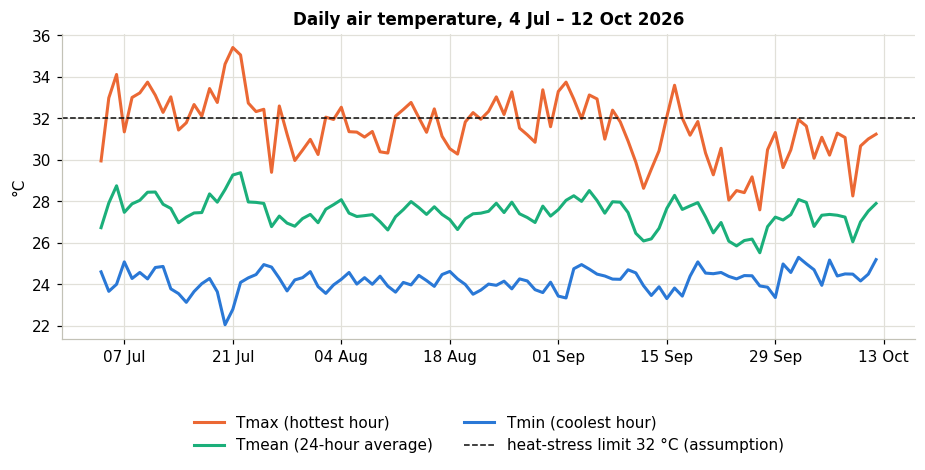

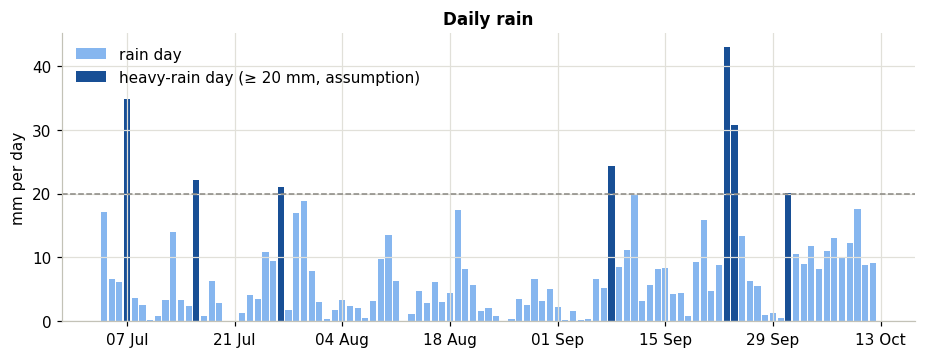

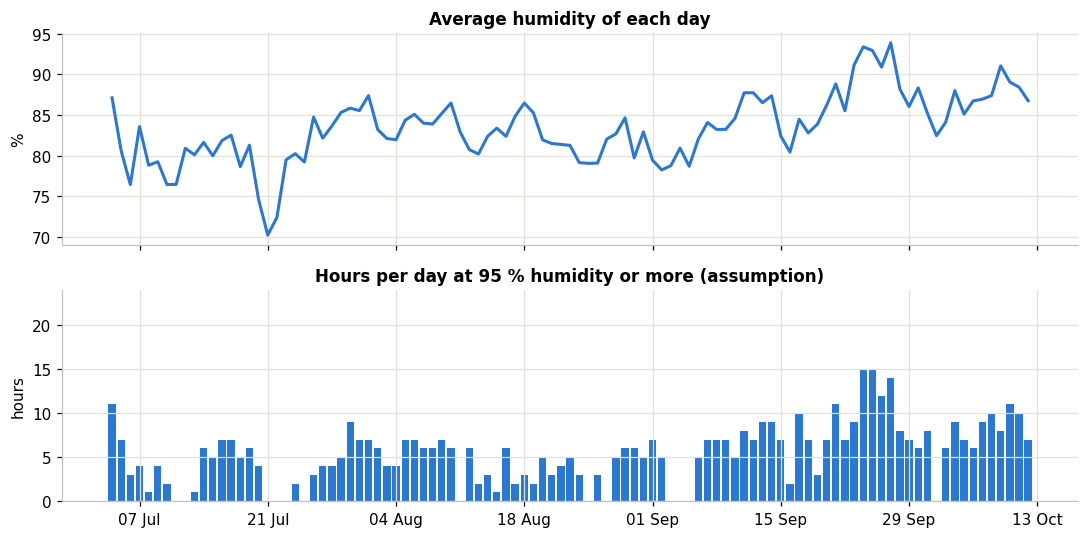

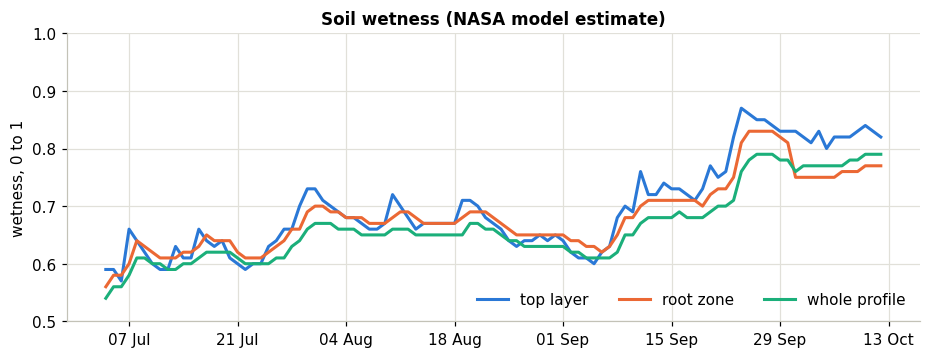

In [14]:
# Temperature: hottest, coolest and average of each day, with the heat-stress limit
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(daily.date, daily.Tmax, color=ORANGE, lw=2, label="Tmax (hottest hour)")
ax.plot(daily.date, daily.Tmean, color=AQUA, lw=2, label="Tmean (24-hour average)")
ax.plot(daily.date, daily.Tmin, color=BLUE, lw=2, label="Tmin (coolest hour)")
ax.axhline(HEAT_C, color="#0b0b0b", ls="--", lw=1, label=f"heat-stress limit {HEAT_C:.0f} °C (assumption)")
ax.set_title("Daily air temperature, 4 Jul – 12 Oct 2026"); ax.set_ylabel("°C"); date_axis(ax)
ax.legend(ncol=2, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.42))
fig.savefig("outputs/charts/2a_daily_temperature.png", bbox_inches="tight"); plt.show()

# Rain: one bar per day. Heavy-rain days are drawn in a darker blue.
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(daily.date[~daily.heavy_rain_day], daily.rain_mm[~daily.heavy_rain_day], color="#86b6ef", width=0.8, label="rain day")
ax.bar(daily.date[daily.heavy_rain_day], daily.rain_mm[daily.heavy_rain_day], color="#184f95", width=0.8,
       label=f"heavy-rain day (≥ {HEAVY_DAY_MM:.0f} mm, assumption)")
ax.axhline(HEAVY_DAY_MM, color=GREY, ls="--", lw=1)
ax.set_title("Daily rain"); ax.set_ylabel("mm per day"); date_axis(ax)
ax.legend(frameon=False, loc="upper left")
fig.savefig("outputs/charts/2b_daily_rain.png", bbox_inches="tight"); plt.show()

# Humidity: daily average (top) and number of very-humid hours per day (bottom)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
a1.plot(daily.date, daily.RH_mean, color=BLUE, lw=2)
a1.set_title("Average humidity of each day"); a1.set_ylabel("%")
a2.bar(daily.date, daily.humid_hours, color=BLUE, width=0.8)
a2.set_title(f"Hours per day at {HUMID_RH:.0f} % humidity or more (assumption)"); a2.set_ylabel("hours"); a2.set_ylim(0, 24)
date_axis(a2); fig.tight_layout()
fig.savefig("outputs/charts/2c_daily_humidity.png", bbox_inches="tight"); plt.show()

# Soil wetness from NASA (0 = dry, 1 = fully wet)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(daily.date, daily.GWETTOP, color=BLUE, lw=2, label="top layer")
ax.plot(daily.date, daily.GWETROOT, color=ORANGE, lw=2, label="root zone")
ax.plot(daily.date, daily.GWETPROF, color=AQUA, lw=2, label="whole profile")
ax.set_title("Soil wetness (NASA model estimate)"); ax.set_ylabel("wetness, 0 to 1"); ax.set_ylim(0.5, 1); date_axis(ax)
ax.legend(ncol=3, frameon=False, loc="lower right")
fig.savefig("outputs/charts/2d_soil_wetness.png", bbox_inches="tight"); plt.show()

**What Step 2 shows.**

* Days are warm to hot: the daily maximum is 27.6–35.4 °C and the minimum 22–25 °C.
  There are **171 heat-stress hours on 41 days** (32 °C or more), mostly in July and August.
* The season is wet (about 750 mm of rain) but heavy-rain days are few: 7 days with 20 mm or more,
  and no single hour reaches 7.6 mm.
* Humidity averages 83 %. It is at 95 % or more for about a fifth of all hours, but only 4 days
  have 12 or more such hours, all late in the season.
* Rain falls in more than nine hours out of ten, mostly as small amounts. This looks like the
  weather model's drizzle, not real shower-by-shower rain, so hourly rain should be read with care.
* The weather is a model average for a grid square about 50 km wide (average height 122 m), not a
  station in the field. Section 2.4 shows how much the answer depends on the square.

# Step 3 — Growing degree days (GDD)

## 3.1 What GDD is

Plants develop faster when it is warm. GDD is a simple way to count "useful warmth":

* every day, take the day's middle temperature: `Tmid = (Tmax + Tmin) / 2` (the form used in the lecture),
* subtract the **base temperature** (below this the plant is assumed not to develop),
* if the answer is below zero, count zero.

`daily GDD = max(0, Tmid − Tbase)`

**Cumulative GDD** is the running total since transplanting. The transplant day is 0 DAT and counts
as 0, so cumulative GDD at 1 DAT is the GDD of the first full day in the field.

We use **Tbase = 10 °C** (main case) and repeat with **15 °C** to see how much the choice matters.
Both are assumptions: the base temperature belongs to the crop, and no project file gives it.

In [15]:
# Daily GDD for both base temperatures (same for every block: they share the same weather)
daily["gdd10"] = (daily.Tmid - TBASE).clip(lower=0)
daily["gdd15"] = (daily.Tmid - TBASE_CHECK).clip(lower=0)
print("daily GDD, base 10:", round(daily.gdd10.min(), 2), "to", round(daily.gdd10.max(), 2), "| mean", round(daily.gdd10.mean(), 2))
print("daily GDD, base 15:", round(daily.gdd15.min(), 2), "to", round(daily.gdd15.max(), 2), "| mean", round(daily.gdd15.mean(), 2))
print("coolest Tmid of the season:", daily.Tmid.min(), "C  -> days where the 'max(0, ...)' rule was needed:",
      int((daily.Tmid < TBASE_CHECK).sum()))

# Cumulative GDD per block, starting from that block's own planting date (0 DAT)
parts = []
for _, b in field.iterrows():
    g = daily.loc[daily.date >= b["planting_date"], ["date", "Tmid", "gdd10", "gdd15"]].copy()
    g.insert(0, "block", b["Block"])
    g["DAT"] = (g.date - b["planting_date"]).dt.days
    for col in ["gdd10", "gdd15"]:
        counted = g[col].where(g.DAT > 0, 0)          # the transplant day itself counts as 0
        g["cum_" + col] = counted.cumsum().round(2)
    parts.append(g)
gdd = pd.concat(parts, ignore_index=True)

check(gdd, "GDD per block per day", "date")
print(gdd.groupby("block").agg(first_day=("date", "min"), last_day=("date", "max"), last_DAT=("DAT", "max"),
                               total_gdd10=("cum_gdd10", "max"), total_gdd15=("cum_gdd15", "max")).to_string())
gdd.to_csv("outputs/tables/gdd_by_block.csv", index=False)

daily GDD, base 10: 15.76 to 19.58 | mean 17.87
daily GDD, base 15: 10.76 to 14.58 | mean 12.87
coolest Tmid of the season: 25.76 C  -> days where the 'max(0, ...)' rule was needed: 0
CHECK GDD per block per day: 398 rows, 8 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 00:00:00
  missing values: none
       first_day   last_day  last_DAT  total_gdd10  total_gdd15
block                                                          
A01   2026-07-04 2026-10-12       100      1787.66      1287.66
A02   2026-07-05 2026-10-12        99      1769.33      1274.33
A03   2026-07-06 2026-10-12        98      1750.27      1260.27
A04   2026-07-07 2026-10-12        97      1732.05      1247.05


## 3.2 Cumulative GDD on each survey day

For every block we read the cumulative GDD on the day of each survey (0, 7, 30, 45, 60, 75 DAT).

In [16]:
# Attach the cumulative GDD of the survey day to each survey row
surveys = surveys.merge(gdd[["block", "date", "cum_gdd10", "cum_gdd15"]],
                        left_on=["block", "survey_date"], right_on=["block", "date"], how="left").drop(columns="date")
check(surveys, "survey dates + GDD", "survey_date")

order = list(stage_names.values())
print("Cumulative GDD (base 10 C) on each survey day")
t10 = surveys.pivot(index="block", columns="stage", values="cum_gdd10")[order]
display(t10)
print("Cumulative GDD (base 15 C) on each survey day")
t15 = surveys.pivot(index="block", columns="stage", values="cum_gdd15")[order]
display(t15)
print("Difference between the highest and lowest block at each stage (base 10), in GDD:")
print((t10.max() - t10.min()).round(1).to_string())
surveys.to_csv("outputs/tables/survey_dates.csv", index=False)

CHECK survey dates + GDD: 24 rows, 8 columns
  dates: 2026-07-04 00:00:00  to  2026-09-20 00:00:00
  missing values: none
Cumulative GDD (base 10 C) on each survey day


stage,Transplant,Establishment,Vegetative,Flowering,Fruit set,First harvest
block,,,,,,
A01,0.0,131.12,547.16,815.14,1085.55,1353.65
A02,0.0,131.37,547.22,814.08,1086.06,1353.11
A03,0.0,130.72,546.12,812.93,1085.47,1352.51
A04,0.0,130.00,545.58,812.61,1086.18,1351.73


Cumulative GDD (base 15 C) on each survey day


stage,Transplant,Establishment,Vegetative,Flowering,Fruit set,First harvest
block,,,,,,
A01,0.0,96.12,397.16,590.14,785.55,978.65
A02,0.0,96.37,397.22,589.08,786.06,978.11
A03,0.0,95.72,396.12,587.93,785.47,977.51
A04,0.0,95.00,395.58,587.61,786.18,976.73


Difference between the highest and lowest block at each stage (base 10), in GDD:
stage
Transplant       0.0
Establishment    1.4
Vegetative       1.6
Flowering        2.5
Fruit set        0.7
First harvest    1.9


## 3.3 Is cumulative GDD just a straight line in days?

If the temperature hardly changes from day to day, every day adds almost the same GDD, and
cumulative GDD grows like a straight line: `cumulative GDD ≈ (GDD per day) × DAT`.
We test this by fitting a straight line through zero for each block and looking at how far the
real curve ever moves away from that line.

In [17]:
rows = []
for block, g in gdd.groupby("block"):
    for col in ["cum_gdd10", "cum_gdd15"]:
        slope = (g.DAT * g[col]).sum() / (g.DAT ** 2).sum()      # best straight line through zero
        gap = g[col] - slope * g.DAT                             # real curve minus straight line
        r2 = 1 - (gap ** 2).sum() / ((g[col] - g[col].mean()) ** 2).sum()
        rows.append({"block": block, "base": col[-2:], "GDD_per_day": round(slope, 2), "R2": round(r2, 5),
                     "largest_gap_GDD": round(gap.abs().max(), 1),
                     "largest_gap_days": round(gap.abs().max() / slope, 2)})
line_fit = pd.DataFrame(rows)
display(line_fit)
print("Day-to-day spread of daily GDD (base 10): standard deviation =", round(daily.gdd10.std(), 2),
      "which is", round(100 * daily.gdd10.std() / daily.gdd10.mean(), 1), "% of the mean")
print("Every day, GDD(base 15) = GDD(base 10) - 5 exactly?", bool(np.allclose(daily.gdd10 - daily.gdd15, 5)))

,block,base,GDD_per_day,R2,largest_gap_GDD,largest_gap_days
0,A01,10,18.01,0.99983,13.5,0.75
1,A01,15,13.01,0.99967,13.5,1.04
2,A02,10,18.00,0.99983,13.3,0.74
3,A02,15,13.00,0.99967,13.3,1.02
4,A03,10,17.99,0.99984,12.7,0.71
5,A03,15,12.99,0.99970,12.7,0.98
6,A04,10,17.98,0.99984,12.5,0.70
7,A04,15,12.98,0.99970,12.5,0.96


Day-to-day spread of daily GDD (base 10): standard deviation = 0.71 which is 4.0 % of the mean
Every day, GDD(base 15) = GDD(base 10) - 5 exactly? True


**What this shows, said plainly.**

* Cumulative GDD is **nearly a straight line in days**. The straight line explains more than 99.9 %
  of it, and the real curve is never more than about one day away from the line.
  In this season, counting GDD is almost the same as counting days.
* This is because temperature changes little: the daily middle temperature stays between about
  26 and 30 °C for the whole season, so every day adds between 16 and 20 GDD.
* **Base 10 vs base 15.** The temperature never drops near either base, so the 15 °C case is exactly
  the 10 °C case minus 5 GDD every day. The totals are different numbers (about 18 vs 13 GDD
  per day), but the **shape is the same**, so changing the base temperature cannot move a
  predicted date by more than a fraction of a day. The data cannot tell us which base is right.
* Consequence for Step 4: GDD will not predict stage dates better than simply counting days here.
  GDD would matter if we compared seasons or places with different temperatures.

## 3.4 Charts

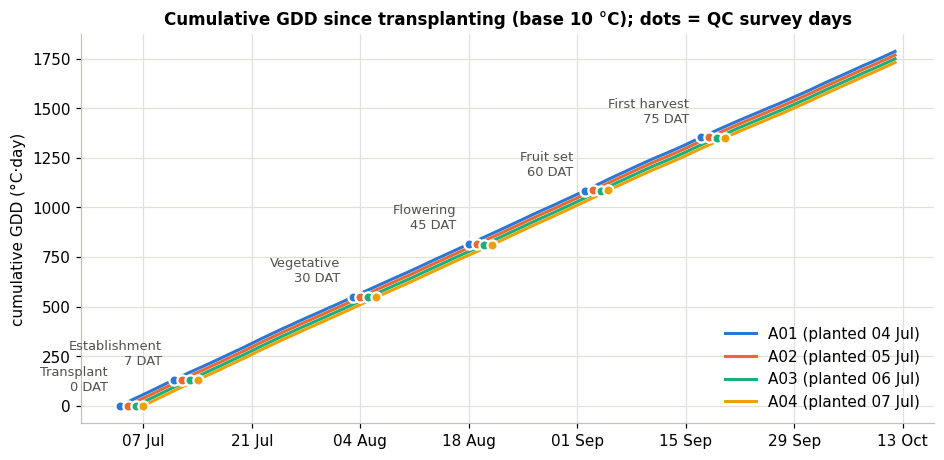

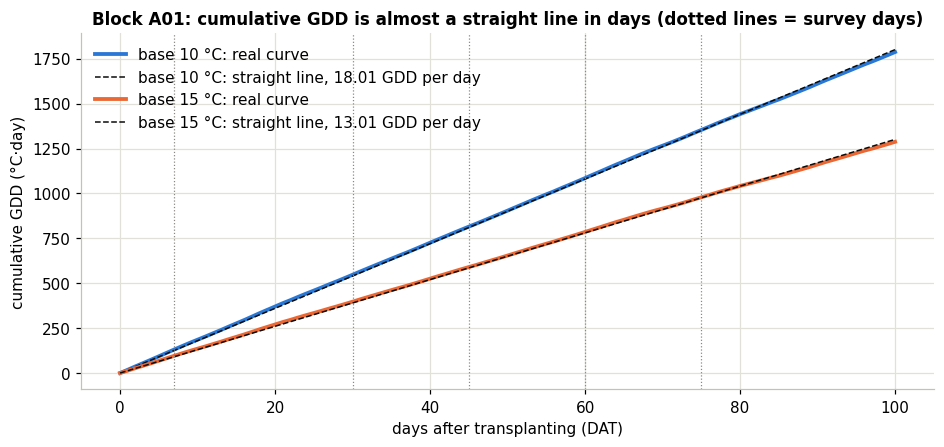

In [18]:
palette = [BLUE, ORANGE, AQUA, YELLOW, "#e87ba4", "#008300", "#6250d6", "#e34948"]
block_colour = {b: palette[i % len(palette)] for i, b in enumerate(field["Block"])}

# Chart 1: cumulative GDD over the calendar, one line per block, survey days marked with dots
fig, ax = plt.subplots(figsize=(10, 4.6))
for block, g in gdd.groupby("block"):
    ax.plot(g.date, g.cum_gdd10, color=block_colour[block], lw=2, label=f"{block} (planted {g.date.min():%d %b})")
    s = surveys[surveys.block == block]
    ax.scatter(s.survey_date, s.cum_gdd10, color=block_colour[block], s=45, zorder=3, edgecolor="white", linewidth=1.5)
# name each survey once, next to the A01 dots
for _, s in surveys[surveys.block == "A01"].iterrows():
    ax.annotate(f"{s.stage}\n{s.DAT} DAT", (s.survey_date, s.cum_gdd10), xytext=(-8, 10), textcoords="offset points",
                ha="right", fontsize=8.5, color="#52514e")
ax.set_title(f"Cumulative GDD since transplanting (base {TBASE:.0f} °C); dots = QC survey days")
ax.set_ylabel("cumulative GDD (°C·day)"); date_axis(ax)
ax.legend(frameon=False, loc="lower right")
fig.savefig("outputs/charts/3a_cumulative_gdd_by_block.png", bbox_inches="tight"); plt.show()

# Chart 2: the same for block A01 against days after transplanting, for both base temperatures,
# with the straight line 'GDD per day x DAT' drawn dashed on top
a01 = gdd[gdd.block == "A01"]
fig, ax = plt.subplots(figsize=(10, 4.2))
for col, colour, label in [("cum_gdd10", BLUE, "base 10 °C"), ("cum_gdd15", ORANGE, "base 15 °C")]:
    slope = line_fit[(line_fit.block == "A01") & (line_fit.base == col[-2:])].GDD_per_day.iloc[0]
    ax.plot(a01.DAT, a01[col], color=colour, lw=2.5, label=f"{label}: real curve")
    ax.plot(a01.DAT, slope * a01.DAT, color="#0b0b0b", lw=1, ls="--",
            label=f"{label}: straight line, {slope} GDD per day")
for d in [7, 30, 45, 60, 75]:
    ax.axvline(d, color=GREY, lw=0.8, ls=":")
ax.set_title("Block A01: cumulative GDD is almost a straight line in days (dotted lines = survey days)")
ax.set_xlabel("days after transplanting (DAT)"); ax.set_ylabel("cumulative GDD (°C·day)")
ax.legend(frameon=False, loc="upper left")
fig.savefig("outputs/charts/3b_gdd_linear_and_base_check.png", bbox_inches="tight"); plt.show()

# Step 4 — Predicting the date of each stage

## 4.1 The model: one GDD threshold per stage

The model is as simple as it can be:

1. For each stage, look at the cumulative GDD the blocks had on the survey day of that stage.
2. The average of those values is the **threshold** of the stage.
3. To predict a stage for a block, find the day when that block's cumulative GDD is closest to the threshold.

With only four blocks, anything more complex would just memorise the data.

In [19]:
# Threshold of each stage = average cumulative GDD of the four blocks on that stage's survey day
thresholds = (surveys.groupby(["stage_no", "stage"])
              .agg(DAT=("DAT", "first"), threshold_gdd10=("cum_gdd10", "mean"), threshold_gdd15=("cum_gdd15", "mean"))
              .round(1).reset_index())
display(thresholds)
thresholds.to_csv("outputs/tables/stage_gdd_thresholds.csv", index=False)

,stage_no,stage,DAT,threshold_gdd10,threshold_gdd15
0,1,Transplant,0,0.0,0.0
1,2,Establishment,7,130.8,95.8
2,3,Vegetative,30,546.5,396.5
3,4,Flowering,45,813.7,588.7
4,5,Fruit set,60,1085.8,785.8
5,6,First harvest,75,1352.8,977.8


## 4.2 Predicted date vs survey date

To be as fair as the data allows, we use **leave-one-block-out**: when we predict block A01, its
threshold is calculated from A02, A03 and A04 only, and so on for each block.

We report two errors:

* `error_days` – predicted date minus survey date, in whole days;
* `gdd_gap_in_days` – how far the block's own GDD was from the threshold, expressed in days
  (a finer measure, because whole days hide small differences).

In [20]:
gdd_per_day = {"cum_gdd10": daily.gdd10.mean(), "cum_gdd15": daily.gdd15.mean()}

def closest_day(block, col, threshold):
    # the day when this block's cumulative GDD is closest to the threshold
    g = gdd[gdd.block == block]
    return g.loc[(g[col] - threshold).abs().idxmin(), "date"]

rows = []
for col in ["cum_gdd10", "cum_gdd15"]:
    for _, s in surveys.iterrows():
        same_stage = surveys[surveys.stage_no == s.stage_no]
        threshold = same_stage[same_stage.block != s.block][col].mean()      # from the OTHER three blocks
        predicted = closest_day(s.block, col, threshold)
        rows.append({"base_C": int(col[-2:]), "block": s.block, "stage_no": s.stage_no, "stage": s.stage, "DAT": s.DAT,
                     "threshold_gdd": round(threshold, 1), "predicted_date": predicted, "survey_date": s.survey_date,
                     "error_days": (predicted - s.survey_date).days,
                     "gdd_gap_in_days": round((s[col] - threshold) / gdd_per_day[col], 2)})
pred = pd.DataFrame(rows)
check(pred, "predicted vs survey dates", "predicted_date")

display(pred[pred.base_C == 10].drop(columns="base_C"))
print("Error summary (all 24 block-stage pairs)")
print(pred.groupby("base_C").agg(mean_abs_error_days=("error_days", lambda e: e.abs().mean()),
                                 largest_error_days=("error_days", lambda e: e.abs().max()),
                                 mean_abs_gdd_gap_days=("gdd_gap_in_days", lambda e: e.abs().mean()),
                                 largest_gdd_gap_days=("gdd_gap_in_days", lambda e: e.abs().max())).round(3).to_string())
same = (pred[pred.base_C == 10].predicted_date.values == pred[pred.base_C == 15].predicted_date.values).all()
print("Are the predicted dates identical for base 10 and base 15?", bool(same))

CHECK predicted vs survey dates: 48 rows, 10 columns
  dates: 2026-07-04 00:00:00  to  2026-09-20 00:00:00
  missing values: none


,block,stage_no,stage,DAT,threshold_gdd,predicted_date,survey_date,error_days,gdd_gap_in_days
0,A01,1,Transplant,0,0.0,2026-07-04,2026-07-04,0,0.00
1,A01,2,Establishment,7,130.7,2026-07-11,2026-07-11,0,0.02
2,A01,3,Vegetative,30,546.3,2026-08-03,2026-08-03,0,0.05
3,A01,4,Flowering,45,813.2,2026-08-18,2026-08-18,0,0.11
4,A01,5,Fruit set,60,1085.9,2026-09-02,2026-09-02,0,-0.02
5,A01,6,First harvest,75,1352.4,2026-09-17,2026-09-17,0,0.07
6,A02,1,Transplant,0,0.0,2026-07-05,2026-07-05,0,0.00
7,A02,2,Establishment,7,130.6,2026-07-12,2026-07-12,0,0.04
8,A02,3,Vegetative,30,546.3,2026-08-04,2026-08-04,0,0.05
9,A02,4,Flowering,45,813.6,2026-08-19,2026-08-19,0,0.03


Error summary (all 24 block-stage pairs)
        mean_abs_error_days  largest_error_days  mean_abs_gdd_gap_days  largest_gdd_gap_days
base_C                                                                                      
10                      0.0                   0                  0.038                  0.11
15                      0.0                   0                  0.052                  0.15
Are the predicted dates identical for base 10 and base 15? True


**Read this result carefully — the error is partly circular.**

The error is zero days, but that does **not** mean the model is very good. It is close to
unavoidable, for three reasons:

1. The "true" dates are **survey days**: planting date + 7, 30, 45, 60, 75 days. They were fixed by
   the calendar, not by what the plants did.
2. The thresholds were calibrated on those same survey days.
3. The four blocks were planted one day apart under the same weather, and GDD grows by almost the
   same amount every day (Step 3). So "GDD on day 45" is the same number for every block.

In plain words: the model learned "flowering survey = 45 days", and then correctly repeated
"45 days". Leave-one-block-out does not fix this, because the left-out block is nearly a copy of
the other three. A model that only counts days would score exactly the same.

## 4.3 Do rainfall and humidity help?

They cannot be tested with this data. To learn whether rain or humidity speeds up or delays a
stage, we need blocks where the stage happened on **different** days under **different** weather.
Here the survey DAT is identical in every block, so there is nothing for rain or humidity to explain.
The table below only *describes* the weather each block had between surveys.

In [21]:
# Weather between one survey and the next, for each block (description only)
rows = []
for block, s in surveys.groupby("block"):
    s = s.sort_values("stage_no")
    for i in range(1, len(s)):
        start, end = s.survey_date.iloc[i - 1], s.survey_date.iloc[i]
        d = daily[(daily.date > start) & (daily.date <= end)]
        rows.append({"block": block, "period": f"{s.stage.iloc[i-1]} -> {s.stage.iloc[i]}", "days": len(d),
                     "rain_mm": round(d.rain_mm.sum(), 1), "heavy_rain_days": int(d.heavy_rain_day.sum()),
                     "RH_mean": round(d.RH_mean.mean(), 1), "humid_hours": int(d.humid_hours.sum()),
                     "heat_hours": int(d.heat_hours.sum())})
stage_weather = pd.DataFrame(rows)
display(stage_weather[stage_weather.block == "A01"])
print("Spread of the survey DAT between blocks, per stage (0 = no difference to explain):")
print(surveys.groupby("stage").DAT.std().to_string())
stage_weather.to_csv("outputs/tables/weather_between_surveys.csv", index=False)

,block,period,days,rain_mm,heavy_rain_days,RH_mean,humid_hours,heat_hours
0,A01,Transplant -> Establishment,7,54.8,1,78.8,21,32
1,A01,Establishment -> Vegetative,23,156.3,2,81.0,92,62
2,A01,Vegetative -> Flowering,15,63.6,0,83.6,66,17
3,A01,Flowering -> Fruit set,15,59.9,0,81.2,59,33
4,A01,Fruit set -> First harvest,15,112.1,1,83.5,83,27


Spread of the survey DAT between blocks, per stage (0 = no difference to explain):
stage
Establishment    0.0
First harvest    0.0
Flowering        0.0
Fruit set        0.0
Transplant       0.0
Vegetative       0.0


## 4.4 When did flowering really start? (category: flowers per plant)

This is **independent evidence**: it comes from counting flowers on plants, not from the calendar.

On the 45 DAT survey, 20 plants per block were checked. If a plant has at least one flower, it has
started flowering. The share of plants with flowers tells us where the block was:

* about 50 % → the block was right at "half the plants flowering" on that day,
* more than 50 % → the block passed that point some days earlier.

**How many days earlier?** We need one assumption: plants in a block do not all start on the same
day. We assume their start days are spread like a bell curve with a spread of 5 days, and repeat
with 3 and 7 days. Then: `half-flowering DAT = 45 − z × spread`, where `z` is the bell-curve value
for the observed share (0 when the share is 50 %).

In [22]:
from statistics import NormalDist

flowers = cat["flowers"]                      # this category only
rows = []
for block, t in flowers.groupby("block"):
    dat = t.DAT.iloc[0]                       # the day of the flowering survey (45 DAT)
    share = (t.flowers > 0).mean()            # share of the 20 plants that have at least one flower
    share = min(max(share, 0.5 / len(t)), 1 - 0.5 / len(t))   # keep 0 % and 100 % usable in the formula
    z = NormalDist().inv_cdf(share)           # bell-curve value for that share
    row = {"block": block, "plants": len(t), "plants_with_flowers": int((t.flowers > 0).sum()),
           "share_%": round(100 * share), "mean_flowers_per_plant": round(t.flowers.mean(), 2),
           "half_flowering_DAT": round(dat - z * FLOWER_SPREAD_DAYS, 1)}
    for sd in FLOWER_SPREAD_CHECK:
        row[f"DAT_if_spread_{sd}"] = round(dat - z * sd, 1)
    rows.append(row)
flowering = pd.DataFrame(rows)

# Turn the estimated DAT into a calendar date and a cumulative GDD (nearest whole day)
flowering = flowering.merge(field[["Block", "planting_date"]], left_on="block", right_on="Block").drop(columns="Block")
flowering["half_flowering_date"] = flowering.planting_date + pd.to_timedelta(flowering.half_flowering_DAT.round(), unit="D")
flowering = flowering.merge(gdd[["block", "date", "cum_gdd10"]], left_on=["block", "half_flowering_date"],
                            right_on=["block", "date"]).drop(columns=["date", "planting_date"])
flowering = flowering.rename(columns={"cum_gdd10": "gdd10_at_half_flowering"})
display(flowering)
print("All blocks together:", int((flowers.flowers > 0).sum()), "of", len(flowers), "plants had flowers at 45 DAT =",
      round(100 * (flowers.flowers > 0).mean(), 1), "%")
print("Calibrated flowering threshold (survey day):", thresholds.threshold_gdd10[thresholds.stage == "Flowering"].iloc[0], "GDD")

,block,plants,plants_with_flowers,share_%,mean_flowers_per_plant,half_flowering_DAT,DAT_if_spread_3,DAT_if_spread_7,half_flowering_date,gdd10_at_half_flowering
0,A01,20,10,50,1.25,45.0,45.0,45.0,2026-08-18,815.14
1,A02,20,16,80,2.20,40.8,42.5,39.1,2026-08-15,743.25
2,A03,20,12,60,1.75,43.7,44.2,43.2,2026-08-19,795.02
3,A04,20,12,60,1.95,43.7,44.2,43.2,2026-08-20,794.71


All blocks together: 50 of 80 plants had flowers at 45 DAT = 62.5 %
Calibrated flowering threshold (survey day): 813.7 GDD


**What this shows.** At 45 DAT, 50 to 80 % of plants had flowers, and they carried only one or two
open flowers each. So the 45 DAT survey caught the crop **right at the start of flowering**:
half-flowering was reached on about day 41 to 45, depending on the block.
The "45 DAT flowering" label is therefore a few days late for some blocks, but not by much.
With 20 plants per block, each share is rough: one plant more or less changes it by 5 points.

## 4.5 When did fruit set really start? (category: young fruits per plant)

On the 60 DAT survey every plant already carried young fruits. So fruit set did not start *at*
60 DAT; it started earlier. A share of 100 % cannot be pushed through the bell-curve method
(it only tells us "before day 60"), so we use the lecture's rule instead:
**young fruits appear about 1 to 2 weeks after flowering.**

In [23]:
fruits = cat["young_fruits"]                  # this category only
fruit_obs = fruits.groupby("block").agg(plants=("young_fruits", "size"),
                                        plants_with_fruit=("young_fruits", lambda v: int((v > 0).sum())),
                                        mean_fruits=("young_fruits", "mean"),
                                        fewest=("young_fruits", "min"), most=("young_fruits", "max")).round(1).reset_index()

# Fruit-set start = half-flowering day + 7 to 14 days (lecture rule)
fruit_set = fruit_obs.merge(flowering[["block", "half_flowering_DAT", "mean_flowers_per_plant"]], on="block")
fruit_set["fruit_set_start_DAT_early"] = fruit_set.half_flowering_DAT + FRUIT_LAG_DAYS[0]
fruit_set["fruit_set_start_DAT_late"]  = fruit_set.half_flowering_DAT + FRUIT_LAG_DAYS[1]
fruit_dat, flower_dat = fruits.DAT.iloc[0], flowers.DAT.iloc[0]                       # 60 and 45
fruit_set["fits_the_60_DAT_survey"] = fruit_set.fruit_set_start_DAT_late <= fruit_dat   # must be before the survey
# 35 fruits at day 60 but only ~2 open flowers at day 45: most flowers opened between the two surveys
fruit_set["fruits_gained_per_day_45_to_60"] = (fruit_set.mean_fruits / (fruit_dat - flower_dat)).round(1)
display(fruit_set)

# Save the estimates of both categories in one small table
onset = flowering[["block", "share_%", "half_flowering_DAT", "half_flowering_date", "gdd10_at_half_flowering"]].merge(
    fruit_set[["block", "fruit_set_start_DAT_early", "fruit_set_start_DAT_late"]], on="block")
onset.to_csv("outputs/tables/flowering_fruitset_estimates.csv", index=False)

,block,plants,plants_with_fruit,mean_fruits,fewest,most,half_flowering_DAT,mean_flowers_per_plant,fruit_set_start_DAT_early,fruit_set_start_DAT_late,fits_the_60_DAT_survey,fruits_gained_per_day_45_to_60
0,A01,20,20,36.8,10,60,45.0,1.25,52.0,59.0,True,2.5
1,A02,20,20,40.8,13,77,40.8,2.20,47.8,54.8,True,2.7
2,A03,20,20,26.6,7,67,43.7,1.75,50.7,57.7,True,1.8
3,A04,20,20,35.8,15,71,43.7,1.95,50.7,57.7,True,2.4


**What this shows.** Fruit set most likely began around day 48 to 59, before the 60 DAT survey
in every block, which agrees with all 80 plants carrying fruit on that day. Plants went from about
2 open flowers at 45 DAT to about 35 young fruits at 60 DAT, so the main flush of flowering
happened **between** the two surveys.

## 4.6 Dates for all 10 stages

Stages 1 to 6 have survey dates, so they get a threshold and a prediction. Stages 7 to 10 have
**no observations at all**, so their dates below come only from the DAT written in the sheet's
headers. The end of the cycle (150 DAT) is after our weather data ends, so it is a plain
projection at the season's average GDD per day. The `basis` column says where each date comes from.

In [24]:
p10 = pred[pred.base_C == 10]
stage_dates = p10[["block", "stage_no", "stage", "DAT", "threshold_gdd", "predicted_date", "survey_date", "error_days"]].copy()
stage_dates["basis"] = "GDD threshold calibrated on survey days (partly circular)"

rate = daily.gdd10.mean()
harvest_start = p10[p10.stage_no == 6].set_index("block")
extra = []
for _, b in field.iterrows():
    blk, planted = b["Block"], b["planting_date"]
    start = harvest_start.loc[blk]
    end_date = planted + pd.Timedelta(days=CYCLE_END_DAT)
    extra += [
        {"block": blk, "stage_no": 7, "stage": "Maturity", "DAT": 75, "threshold_gdd": start.threshold_gdd,
         "predicted_date": start.predicted_date, "basis": "sheet header '75 DAT+'; no observations"},
        {"block": blk, "stage_no": 8, "stage": "Harvest (start)", "DAT": 75, "threshold_gdd": start.threshold_gdd,
         "predicted_date": start.predicted_date, "basis": "sheet header '75-150 DAT'; one harvest recorded on 12 Oct"},
        {"block": blk, "stage_no": 9, "stage": "Plant health (start)", "DAT": 75, "threshold_gdd": start.threshold_gdd,
         "predicted_date": start.predicted_date, "basis": "sheet header '75-150 DAT'; no observations"},
        {"block": blk, "stage_no": 10, "stage": "End of cycle", "DAT": CYCLE_END_DAT,
         "threshold_gdd": round(rate * CYCLE_END_DAT, 1), "predicted_date": end_date,
         "basis": "projection: 150 DAT x average GDD per day; beyond the weather data"},
    ]
stage_dates = pd.concat([stage_dates, pd.DataFrame(extra)], ignore_index=True).sort_values(["block", "stage_no"])
check(stage_dates, "stage dates, all 10 stages", "predicted_date")
display(stage_dates[stage_dates.block == "A01"])
stage_dates.to_csv("outputs/tables/stage_dates.csv", index=False)

# The one recorded harvest: 12 Oct for all blocks
print("Recorded harvest on 12 Oct 2026:")
print(gdd[gdd.date == SEASON_END][["block", "DAT", "cum_gdd10"]].to_string(index=False))

CHECK stage dates, all 10 stages: 40 rows, 9 columns
  dates: 2026-07-04 00:00:00  to  2026-12-04 00:00:00
  missing values: {'survey_date': 16, 'error_days': 16}


,block,stage_no,stage,DAT,threshold_gdd,predicted_date,survey_date,error_days,basis
0,A01,1,Transplant,0,0.0,2026-07-04,2026-07-04,0.0,GDD threshold calibrated on survey days (partl...
1,A01,2,Establishment,7,130.7,2026-07-11,2026-07-11,0.0,GDD threshold calibrated on survey days (partl...
2,A01,3,Vegetative,30,546.3,2026-08-03,2026-08-03,0.0,GDD threshold calibrated on survey days (partl...
3,A01,4,Flowering,45,813.2,2026-08-18,2026-08-18,0.0,GDD threshold calibrated on survey days (partl...
4,A01,5,Fruit set,60,1085.9,2026-09-02,2026-09-02,0.0,GDD threshold calibrated on survey days (partl...
5,A01,6,First harvest,75,1352.4,2026-09-17,2026-09-17,0.0,GDD threshold calibrated on survey days (partl...
24,A01,7,Maturity,75,1352.4,2026-09-17,NaT,NaN,sheet header '75 DAT+'; no observations
25,A01,8,Harvest (start),75,1352.4,2026-09-17,NaT,NaN,sheet header '75-150 DAT'; one harvest recorde...
26,A01,9,Plant health (start),75,1352.4,2026-09-17,NaT,NaN,sheet header '75-150 DAT'; no observations
27,A01,10,End of cycle,150,2680.6,2026-12-01,NaT,NaN,projection: 150 DAT x average GDD per day; bey...


Recorded harvest on 12 Oct 2026:
block  DAT  cum_gdd10
  A01  100    1787.66
  A02   99    1769.33
  A03   98    1750.27
  A04   97    1732.05


## 4.7 Charts

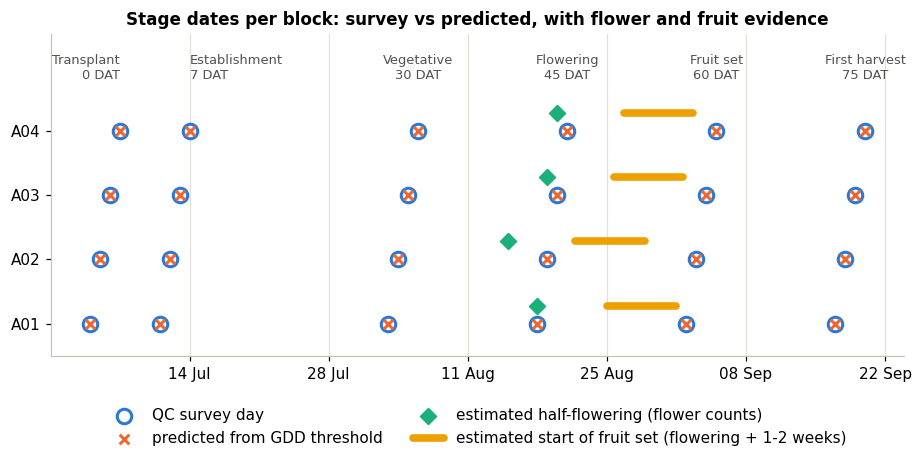

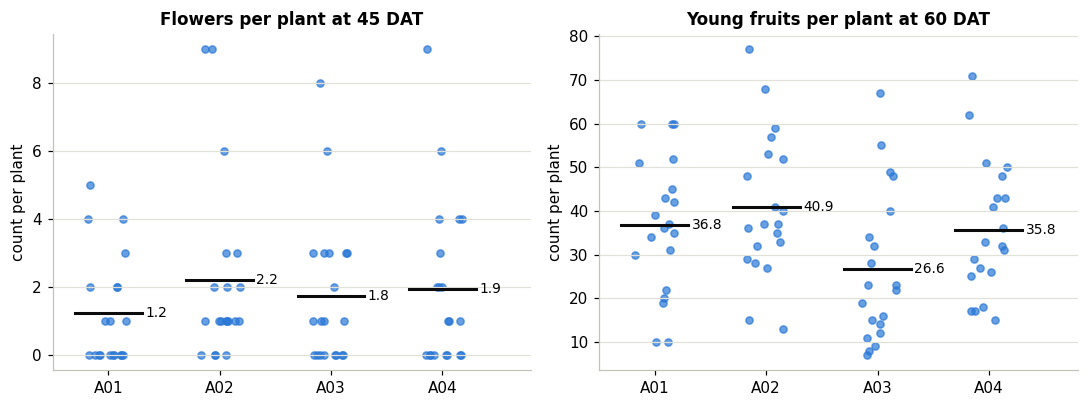

In [25]:
# Chart 1: timeline per block. Circle = survey day, cross = predicted day,
# diamond = estimated half-flowering, thick bar = estimated start of fruit set.
fig, ax = plt.subplots(figsize=(10, 3.8))
blocks = list(field["Block"])
for i, blk in enumerate(blocks):
    s = p10[p10.block == blk]
    ax.scatter(s.survey_date, [i] * len(s), s=90, facecolor="white", edgecolor=BLUE, linewidth=2, zorder=3,
               label="QC survey day" if i == 0 else None)
    ax.scatter(s.predicted_date, [i] * len(s), s=40, marker="x", color=ORANGE, linewidth=2, zorder=4,
               label="predicted from GDD threshold" if i == 0 else None)
    o = onset[onset.block == blk].iloc[0]
    planted = field.loc[field["Block"] == blk, "planting_date"].iloc[0]
    ax.scatter(o.half_flowering_date, i + 0.28, s=55, marker="D", color=AQUA, zorder=4,
               label="estimated half-flowering (flower counts)" if i == 0 else None)
    ax.plot([planted + pd.Timedelta(days=o.fruit_set_start_DAT_early), planted + pd.Timedelta(days=o.fruit_set_start_DAT_late)],
            [i + 0.28] * 2, color=YELLOW, lw=5, solid_capstyle="round", zorder=2,
            label="estimated start of fruit set (flowering + 1-2 weeks)" if i == 0 else None)
for _, s in p10[p10.block == blocks[-1]].iterrows():
    side = {1: "right", 2: "left"}.get(s.stage_no, "center")      # keep the first two labels apart
    ax.text(s.survey_date, len(blocks) - 0.25, f"{s.stage}\n{s.DAT} DAT", ha=side, va="bottom", fontsize=8.5, color="#52514e")
ax.set_yticks(range(len(blocks))); ax.set_yticklabels(blocks); ax.set_ylim(-0.5, len(blocks) + 0.5)
ax.set_title("Stage dates per block: survey vs predicted, with flower and fruit evidence"); date_axis(ax)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.savefig("outputs/charts/4a_stage_dates_timeline.png", bbox_inches="tight"); plt.show()

# Chart 2: what the plants showed. Each dot is one plant; the black line is the block average.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
rng = np.random.default_rng(0)                         # fixed seed so the chart is the same every run
for ax, table, value, title in [(axes[0], flowers, "flowers", "Flowers per plant at 45 DAT"),
                                (axes[1], fruits, "young_fruits", "Young fruits per plant at 60 DAT")]:
    for i, (blk, t) in enumerate(table.groupby("block")):
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(t)), t[value], s=22, color=BLUE, alpha=0.7)
        ax.plot([i - 0.3, i + 0.3], [t[value].mean()] * 2, color="#0b0b0b", lw=2)
        ax.text(i + 0.33, t[value].mean(), f"{t[value].mean():.1f}", va="center", fontsize=9)
    ax.set_xticks(range(len(blocks))); ax.set_xticklabels(blocks); ax.set_xlim(-0.5, len(blocks) - 0.2)
    ax.set_title(title); ax.set_ylabel("count per plant"); ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("outputs/charts/4b_flowers_and_fruits_per_plant.png", bbox_inches="tight"); plt.show()

## 4.8 What this model can and cannot show

**It can show**

* how much warmth (GDD) the crop had collected by each survey day – a reference set of thresholds
  for Red Sky 86 F1 in this field and season;
* that these numbers are the same in all four blocks, so the method is consistent;
* from the plant counts: flowering was just starting at 45 DAT, and fruit set started before 60 DAT.

**It cannot show**

* the real day each stage began. The field dates are planned visits, so the "error in days" only
  measures how well we reproduce the visit calendar;
* that GDD is better than counting days. Temperature was too steady for the two to differ;
* which base temperature is right. Base 10 and base 15 give the same dates;
* any effect of rain or humidity on timing. All blocks had the same weather and the same survey days;
* how it would perform in another season or place. It has never been tested on different weather.

**What would make it a real test:** record the actual date of first flower, 50 % flowering and
first ripe fruit in each block, and include blocks planted weeks apart (the sheet lists planting
dates from July to October for other blocks, but they have no observations yet).

# Step 5 — Weather stress and yield

## 5.1 Stress days

A **stress day** is a day when the weather crossed one of our limits:

* **heat day** – at least one hour at 32 °C or more,
* **heavy-rain day** – 20 mm of rain or more in the day,
* **very-humid day** – 12 or more hours at 95 % humidity or more.

All three limits are assumptions (set in the settings cell). We count the stress days of each block
in four parts of its life, using days after transplanting (DAT):

| Part | DAT | Why |
|---|---|---|
| Establishment | 0–7 | up to the establishment survey |
| Vegetative | 8–39 | leaf and branch growth |
| Flowering & fruit set | 40–75 | from just before half-flowering (Step 4) to first harvest; the **sensitive window** |
| Harvest | 76 onward | picking period, up to 12 October |

In [26]:
# Mark each day of the season as a stress day or not
daily["heat_day"]  = daily.heat_hours > 0
daily["humid_day"] = daily.humid_hours >= HUMID_DAY_HOURS
print("Stress days in the whole season (", len(daily), "days )")
print("  heat days:", int(daily.heat_day.sum()))
print("  heavy-rain days:", int(daily.heavy_rain_day.sum()))
print("  very-humid days:", int(daily.humid_day.sum()))
print("  days that are both heavy-rain and very-humid:", int((daily.heavy_rain_day & daily.humid_day).sum()))

# Give every day of every block its DAT and its part of the crop's life
parts = []
phase_names = ["Establishment", "Vegetative", "Flowering & fruit set", "Harvest"]
for _, b in field.iterrows():
    d = daily.loc[daily.date >= b["planting_date"],
                  ["date", "rain_mm", "humid_hours", "heat_day", "heavy_rain_day", "humid_day"]].copy()
    d.insert(0, "block", b["Block"])
    d["DAT"] = (d.date - b["planting_date"]).dt.days
    d["phase"] = pd.cut(d.DAT, bins=[-1, 7, SENSITIVE_DAT[0] - 1, SENSITIVE_DAT[1], 10000], labels=phase_names)
    parts.append(d)
stress = pd.concat(parts, ignore_index=True)
check(stress, "stress days per block per day", "date")

stress_summary = (stress.groupby(["block", "phase"], observed=True)
                  .agg(days=("date", "size"), rain_mm=("rain_mm", "sum"), heat_days=("heat_day", "sum"),
                       heavy_rain_days=("heavy_rain_day", "sum"), humid_days=("humid_day", "sum"))
                  .round(1).reset_index())
display(stress_summary)
stress_summary.to_csv("outputs/tables/stress_days_by_phase.csv", index=False)
daily.to_csv("outputs/tables/daily_weather.csv", index=False)       # save again, now with the stress-day columns

Stress days in the whole season ( 101 days )
  heat days: 41
  heavy-rain days: 7
  very-humid days: 4
  days that are both heavy-rain and very-humid: 1
CHECK stress days per block per day: 398 rows, 9 columns
  dates: 2026-07-04 00:00:00  to  2026-10-12 00:00:00
  missing values: none


,block,phase,days,rain_mm,heat_days,heavy_rain_days,humid_days
0,A01,Establishment,8,71.9,6,1,0
1,A01,Vegetative,32,197.4,17,2,0
2,A01,Flowering & fruit set,36,194.4,18,1,0
3,A01,Harvest,25,282.8,0,3,4
4,A02,Establishment,8,58.2,7,1,0
5,A02,Vegetative,32,195.2,17,2,0
6,A02,Flowering & fruit set,36,194.2,17,1,0
7,A02,Harvest,24,281.9,0,3,4
8,A03,Establishment,8,65.4,7,1,0
9,A03,Vegetative,32,186.0,17,2,0


**What this shows.** Heat is the main stress. Heat days fall in the first three parts of the
crop's life, including 16–18 of the 36 days of the sensitive window, and stop before the harvest
period. Heavy-rain days are few (1 in the sensitive window), and very-humid days appear only
during harvest.

## 5.2 Each plant category, fitted on its own

Following the teacher's rule, each category table is analysed **separately**. For each one we fit the
simplest possible model: *a plant's value = its block's average + plant-to-plant noise*.
`block_effect_R2` says how much of the difference between plants is explained by which block they
are in (0 = blocks are the same, 1 = block explains everything).

Where a project file gives a reference, we compare against it:

* vigor score – QC guideline: 4–5 green, 3 to below 4 yellow, below 3 red;
* fruit length and diameter – planting guide: 6.5–7.8 cm and 1.1–1.2 cm.

Height, canopy, branching, flowers and young fruits have **no reference value** in the files (the
guideline says "compare with a healthy farm baseline", which we do not have).

In [27]:
reference = {"fruit_length": (6.5, 7.8), "fruit_diameter": (1.1, 1.2)}     # planting guide ranges
rows = []
for name, t in cat.items():
    value = "canopy_mean" if name == "canopy" else name
    block_mean = t.groupby("block")[value].transform("mean")
    between = ((block_mean - t[value].mean()) ** 2).sum()       # differences between blocks
    total = ((t[value] - t[value].mean()) ** 2).sum()           # all differences between plants
    row = {"category": name, "DAT": t.DAT.iloc[0], "plants": len(t), "mean": round(t[value].mean(), 2),
           "std": round(t[value].std(), 2), "block_effect_R2": round(between / total, 3),
           "lowest_block_mean": round(t.groupby("block")[value].mean().min(), 2),
           "highest_block_mean": round(t.groupby("block")[value].mean().max(), 2), "reference": "none in files",
           "share_meeting_reference_%": np.nan}
    if name in reference:
        low, high = reference[name]
        row["reference"] = f"{low}-{high} cm (planting guide)"
        row["share_meeting_reference_%"] = round(100 * (t[value] >= low).mean(), 1)     # at or above the lower end
    if name == "vigor":
        row["reference"] = "4-5 green (QC guideline)"
        row["share_meeting_reference_%"] = round(100 * (t[value] >= 4).mean(), 1)
    rows.append(row)
category_fit = pd.DataFrame(rows)
display(category_fit)
category_fit.to_csv("outputs/tables/category_fit_summary.csv", index=False)

vigor = cat["vigor"].vigor
print("Vigor classes over all plants: green (4-5):", int((vigor >= 4).sum()), "| yellow (3):", int(((vigor >= 3) & (vigor < 4)).sum()),
      "| red (<3):", int((vigor < 3).sum()))

,category,DAT,plants,mean,std,block_effect_R2,lowest_block_mean,highest_block_mean,reference,share_meeting_reference_%
0,vigor,30,80,3.71,0.87,0.007,3.60,3.80,4-5 green (QC guideline),66.2
1,height,30,80,32.83,9.07,0.041,31.01,35.78,none in files,NaN
2,branching,30,80,4.38,1.94,0.012,4.05,4.65,none in files,NaN
3,flowers,45,80,1.79,2.26,0.024,1.25,2.20,none in files,NaN
4,young_fruits,60,80,35.00,16.68,0.099,26.60,40.85,none in files,NaN
5,fruit_length,75,80,6.19,0.65,0.497,5.69,6.70,6.5-7.8 cm (planting guide),47.5
6,fruit_diameter,75,80,0.86,0.11,0.105,0.84,0.92,1.1-1.2 cm (planting guide),0.0
7,canopy,30,80,15.72,4.32,0.030,14.58,16.68,none in files,NaN


Vigor classes over all plants: green (4-5): 53 | yellow (3): 18 | red (<3): 9


**What this shows.**

* In seven of the eight categories the block explains only a small part of the differences (10 %
  or less). Plants differ far more **inside** a block than **between** blocks.
* **Fruit length is the exception:** the block explains about half of the differences. Fruit in A01
  and A02 averages about 6.6–6.7 cm, in A03 and A04 about 5.7–5.8 cm. The files do not say why.
* Vigor averages about 3.7, in the guideline's yellow band ("moderate or uneven").
* Fruit at the 75 DAT survey is **smaller than the seed company's figures**, especially in
  diameter: no measured fruit reaches 1.1 cm. The fruit may not have been fully grown on that day,
  but it is a warning that the guide's 1.5–1.6 kg per plant may be optimistic for this field.
  We do **not** turn this into a yield number, because no file links fruit size to weight.

## 5.3 Yield loss from weather (assumption-based)

There is **no measured yield** in the sheet, so a loss cannot be measured. We use a simple, clearly
labelled rule instead:

`loss % = 0.5 × heat days + 0.5 × heavy-rain days + 0.25 × very-humid days`, counted only in the
sensitive window (40–75 DAT), and never more than 30 %. A day can count under more than one type.

To show how much the answer depends on the assumed rates, we also compute the loss with the rates
halved and doubled.

In [28]:
window = stress[stress.phase == "Flowering & fruit set"]
loss = window.groupby("block").agg(window_days=("date", "size"), heat_days=("heat_day", "sum"),
                                   heavy_rain_days=("heavy_rain_day", "sum"), humid_days=("humid_day", "sum")).reset_index()

def loss_percent(table, factor=1.0):
    # the assumed rule, with an optional factor to test lower or higher rates
    raw = factor * (LOSS_PER_HEAT_DAY * table.heat_days + LOSS_PER_HEAVY_RAIN_DAY * table.heavy_rain_days
                    + LOSS_PER_HUMID_DAY * table.humid_days)
    return raw.clip(upper=LOSS_CAP).round(2)

loss["loss_%"] = loss_percent(loss)
loss["loss_%_if_rates_halved"]  = loss_percent(loss, 0.5)
loss["loss_%_if_rates_doubled"] = loss_percent(loss, 2.0)
display(loss)

,block,window_days,heat_days,heavy_rain_days,humid_days,loss_%,loss_%_if_rates_halved,loss_%_if_rates_doubled
0,A01,36,18,1,0,9.5,4.75,19.0
1,A02,36,17,1,0,9.0,4.50,18.0
2,A03,36,16,1,0,8.5,4.25,17.0
3,A04,36,16,1,0,8.5,4.25,17.0


## 5.4 Potential yield and yield after loss

* **Potential yield** = 12,500 plants × 1.5 kg (base case) or × 1.6 kg (upper case).
* **Yield after weather loss** = potential × (1 − loss %).

As a side check from field data: at 7 DAT, 18–19 of the 20 sampled plants were alive. If that
survival held for the whole block and dead plants were not replaced, fewer plants would be
harvested. We show that as an extra column, but the main numbers use 12,500 plants as instructed.

In [29]:
# Survival at 7 DAT from the field sheet (live and dead plants in the 20-plant sample)
live = pd.to_numeric(field["S2|Plant Survival (No.)|Live Plant"])
dead = pd.to_numeric(field["S2|Plant Survival (No.)|Dead Plant"])
survival = pd.DataFrame({"block": field["Block"], "survival_7DAT_%": (100 * live / (live + dead)).round(1)})

yields = loss[["block", "loss_%"]].merge(survival, on="block")
yields["potential_kg_base"]  = PLANTS_PER_BLOCK * YIELD_KG_BASE
yields["potential_kg_upper"] = PLANTS_PER_BLOCK * YIELD_KG_UPPER
yields["after_loss_kg_base"]  = (yields.potential_kg_base  * (1 - yields["loss_%"] / 100)).round(0)
yields["after_loss_kg_upper"] = (yields.potential_kg_upper * (1 - yields["loss_%"] / 100)).round(0)
yields["lost_kg_base"] = yields.potential_kg_base - yields.after_loss_kg_base
yields["after_loss_kg_base_if_7DAT_survival_held"] = (yields.after_loss_kg_base * yields["survival_7DAT_%"] / 100).round(0)
display(yields)

total = yields[["potential_kg_base", "after_loss_kg_base", "lost_kg_base", "potential_kg_upper", "after_loss_kg_upper"]].sum()
print("All blocks together (kg):")
print(total.to_string())
yields.to_csv("outputs/tables/yield_summary.csv", index=False)

,block,loss_%,survival_7DAT_%,potential_kg_base,potential_kg_upper,after_loss_kg_base,after_loss_kg_upper,lost_kg_base,after_loss_kg_base_if_7DAT_survival_held
0,A01,9.5,90.0,18750.0,20000.0,16969.0,18100.0,1781.0,15272.0
1,A02,9.0,95.0,18750.0,20000.0,17062.0,18200.0,1688.0,16209.0
2,A03,8.5,90.0,18750.0,20000.0,17156.0,18300.0,1594.0,15440.0
3,A04,8.5,95.0,18750.0,20000.0,17156.0,18300.0,1594.0,16298.0


All blocks together (kg):
potential_kg_base      75000.0
after_loss_kg_base     68343.0
lost_kg_base            6657.0
potential_kg_upper     80000.0
after_loss_kg_upper    72900.0


## 5.5 Daily yield from first harvest to the end of the season

Chili is picked several times. The sheet has room for **5 harvests** but gives no dates between them;
it records the first-harvest survey (75 DAT) and one harvest on 12 October.

**Assumption:** the 5 harvests are spread evenly from the block's first-harvest day to 12 October,
and each harvest brings in one fifth of the block's yield. On days without a harvest the yield is 0.
We also give the **average per day** over the harvest period, which is easier to compare.

In [30]:
first_harvest = surveys[surveys.stage_no == 6].set_index("block").survey_date
rows = []
for _, y in yields.iterrows():
    start = first_harvest[y.block]
    span = SEASON_END - start
    harvest_days = [(start + span * i / (N_HARVESTS - 1)).round("D") for i in range(N_HARVESTS)]   # evenly spaced
    for day in pd.date_range(start, SEASON_END):
        n = harvest_days.index(day) + 1 if day in harvest_days else 0
        rows.append({"date": day, "block": y.block, "harvest_no": n,
                     "yield_kg_base":  y.after_loss_kg_base  / N_HARVESTS if n else 0.0,
                     "yield_kg_upper": y.after_loss_kg_upper / N_HARVESTS if n else 0.0})
daily_yield = pd.DataFrame(rows)
daily_yield["cumulative_kg_base"]  = daily_yield.groupby("block").yield_kg_base.cumsum()
daily_yield["cumulative_kg_upper"] = daily_yield.groupby("block").yield_kg_upper.cumsum()
check(daily_yield, "daily yield per block", "date")

print("Harvest days and kg per harvest (base case, after weather loss):")
display(daily_yield[daily_yield.harvest_no > 0].pivot(index="harvest_no", columns="block", values="date"))
per_block = daily_yield.groupby("block").agg(harvest_period_days=("date", "size"), total_kg_base=("yield_kg_base", "sum"),
                                             total_kg_upper=("yield_kg_upper", "sum"))
per_block["kg_per_harvest_base"] = per_block.total_kg_base / N_HARVESTS
per_block["average_kg_per_day_base"] = (per_block.total_kg_base / per_block.harvest_period_days).round(0)
display(per_block)

# All blocks added together, day by day
farm_daily = daily_yield.groupby("date")[["yield_kg_base", "yield_kg_upper"]].sum().reset_index()
farm_daily["cumulative_kg_base"] = farm_daily.yield_kg_base.cumsum()
farm_daily["cumulative_kg_upper"] = farm_daily.yield_kg_upper.cumsum()
daily_yield.to_csv("outputs/tables/daily_yield.csv", index=False)
farm_daily.to_csv("outputs/tables/daily_yield_all_blocks.csv", index=False)

CHECK daily yield per block: 98 rows, 7 columns
  dates: 2026-09-17 00:00:00  to  2026-10-12 00:00:00
  missing values: none
Harvest days and kg per harvest (base case, after weather loss):


block,A01,A02,A03,A04
harvest_no,,,,
1,2026-09-17,2026-09-18,2026-09-19,2026-09-20
2,2026-09-23,2026-09-24,2026-09-25,2026-09-26
3,2026-09-30,2026-09-30,2026-09-30,2026-10-01
4,2026-10-06,2026-10-06,2026-10-06,2026-10-06
5,2026-10-12,2026-10-12,2026-10-12,2026-10-12


,harvest_period_days,total_kg_base,total_kg_upper,kg_per_harvest_base,average_kg_per_day_base
block,,,,,
A01,26,16969.0,18100.0,3393.8,653.0
A02,25,17062.0,18200.0,3412.4,682.0
A03,24,17156.0,18300.0,3431.2,715.0
A04,23,17156.0,18300.0,3431.2,746.0


## 5.6 Charts

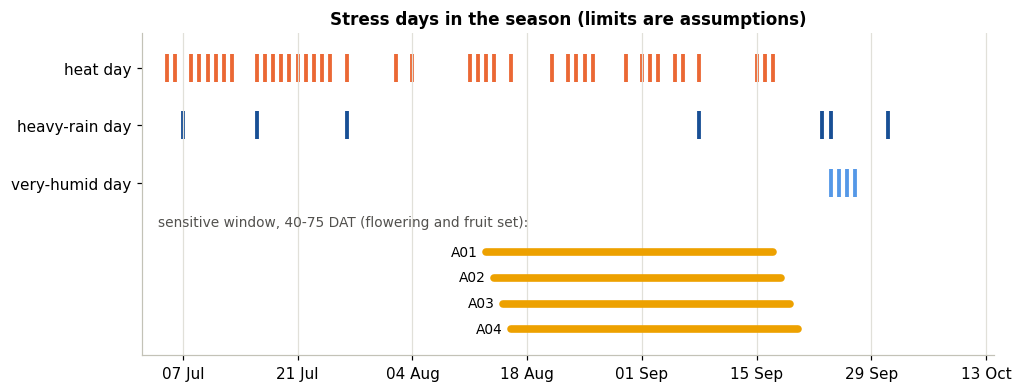

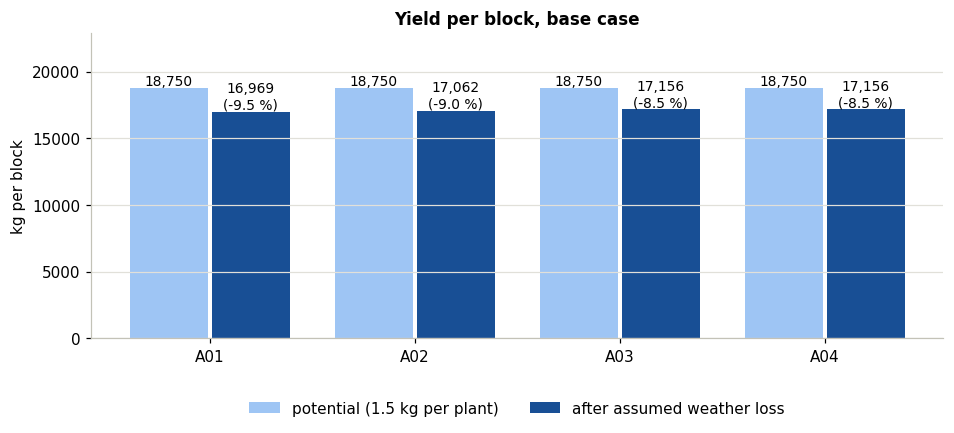

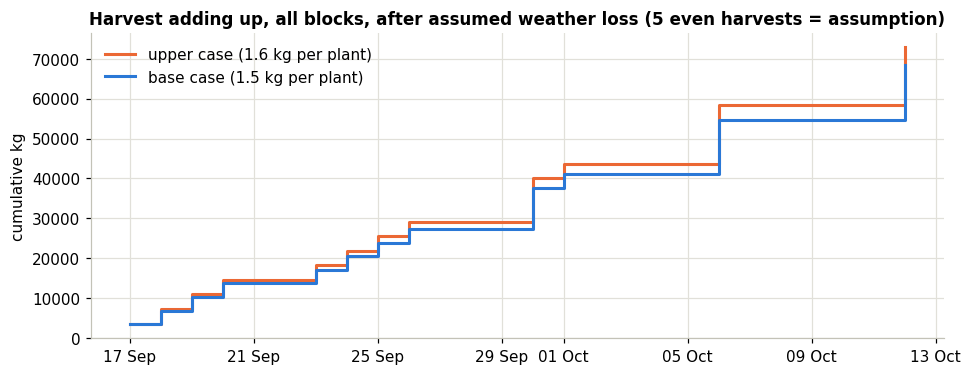

In [31]:
# Chart 1: stress calendar. Each mark is one stress day; the bars show each block's sensitive window.
fig, ax = plt.subplots(figsize=(10, 3.8))
rows_y = {"heat day": 2, "heavy-rain day": 1, "very-humid day": 0}
ax.scatter(daily.date[daily.heavy_rain_day], [1] * int(daily.heavy_rain_day.sum()), marker="|", s=320, color="#184f95", linewidth=2.5)
ax.scatter(daily.date[daily.humid_day], [0] * int(daily.humid_day.sum()), marker="|", s=320, color="#5598e7", linewidth=2.5)
ax.scatter(daily.date[daily.heat_day], [2] * int(daily.heat_day.sum()), marker="|", s=320, color=ORANGE, linewidth=2.5)
for i, (_, b) in enumerate(field.iterrows()):
    y = -1.2 - 0.45 * i
    ax.plot([b["planting_date"] + pd.Timedelta(days=SENSITIVE_DAT[0]), b["planting_date"] + pd.Timedelta(days=SENSITIVE_DAT[1])],
            [y, y], color=YELLOW, lw=5, solid_capstyle="round")
    ax.text(b["planting_date"] + pd.Timedelta(days=SENSITIVE_DAT[0] - 1), y, b["Block"], ha="right", va="center", fontsize=9)
ax.text(daily.date.iloc[0], -0.75, f"sensitive window, {SENSITIVE_DAT[0]}-{SENSITIVE_DAT[1]} DAT (flowering and fruit set):", fontsize=9, color="#52514e")
ax.set_yticks(list(rows_y.values())); ax.set_yticklabels(list(rows_y.keys()))
ax.set_ylim(-1.2 - 0.45 * len(field), 2.6); ax.grid(axis="y", visible=False); date_axis(ax)
ax.set_xlim(SEASON_START - pd.Timedelta(days=2), SEASON_END + pd.Timedelta(days=2))     # show the whole season
ax.set_title("Stress days in the season (limits are assumptions)")
fig.savefig("outputs/charts/5a_stress_calendar.png", bbox_inches="tight"); plt.show()

# Chart 2: potential yield and yield after the assumed weather loss, per block (base case)
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(yields))
ax.bar(x - 0.2, yields.potential_kg_base, width=0.38, color="#9ec5f4", label=f"potential ({YIELD_KG_BASE} kg per plant)")
ax.bar(x + 0.2, yields.after_loss_kg_base, width=0.38, color="#184f95", label="after assumed weather loss")
for i, y in yields.iterrows():
    ax.text(i - 0.2, y.potential_kg_base + 250, f"{y.potential_kg_base:,.0f}", ha="center", fontsize=9)
    ax.text(i + 0.2, y.after_loss_kg_base + 250, f"{y.after_loss_kg_base:,.0f}\n(-{y['loss_%']:.1f} %)", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(yields.block); ax.set_ylabel("kg per block"); ax.set_ylim(0, yields.potential_kg_base.max() * 1.22)
ax.set_title("Yield per block, base case"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2)
fig.savefig("outputs/charts/5b_yield_per_block.png", bbox_inches="tight"); plt.show()

# Chart 3: harvested kg adding up over the harvest period, all four blocks together
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.step(farm_daily.date, farm_daily.cumulative_kg_upper, where="post", color=ORANGE, lw=2, label=f"upper case ({YIELD_KG_UPPER} kg per plant)")
ax.step(farm_daily.date, farm_daily.cumulative_kg_base, where="post", color=BLUE, lw=2, label=f"base case ({YIELD_KG_BASE} kg per plant)")
ax.set_title("Harvest adding up, all blocks, after assumed weather loss (5 even harvests = assumption)")
ax.set_ylabel("cumulative kg"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(frameon=False, loc="upper left")
fig.savefig("outputs/charts/5c_cumulative_harvest.png", bbox_inches="tight"); plt.show()

## 5.7 Which numbers come from data and which are assumptions

| Number | Value | Where it comes from |
|---|---|---|
| Planting and survey dates, plant counts and measurements | – | **field data** (QC sheet) |
| Hourly temperature, humidity, rain; soil wetness | – | **NASA POWER model data** for the field's grid square (12.14 N, 104.08 E), not a field station |
| Plants per block | 12,500 | given constant (0.5 ha × 25,000 plants per ha) |
| Yield per plant | 1.5 and 1.6 kg | seed company planting guide, **not measured here** |
| First harvest | 75 DAT | field sheet and planting guide |
| Number of harvests | 5 | number of harvest columns in the sheet |
| Harvest spacing and equal split | even | **assumption** |
| Base temperature | 10 °C (15 °C check) | **assumption** |
| Heat limit, heavy-rain limits, humidity limit | 32 °C; 7.6 mm/hour and 20 mm/day; 95 % | **assumption** |
| Very-humid day | 12 hours or more | **assumption** |
| Sensitive window | 40–75 DAT | **assumption**, guided by the flower and fruit counts |
| Loss per stress day and the 30 % cap | 0.5 % (heat), 0.5 % (heavy rain), 0.25 % (very humid), 30 % | **assumption** |
| Flowering spread between plants | 5 days (3 and 7 check) | **assumption** |

The yield and loss figures are therefore **scenarios**, not measurements. They show how the
calculation works and what it would give under these assumptions.

# Step 6 — Summary of results and limits

In [32]:
# The key numbers in one place (all taken from the tables made above)
print("SEASON:", f"{SEASON_START:%d %b %Y} to {SEASON_END:%d %b %Y}", "|", len(daily), "days | blocks:", ", ".join(field["Block"]))
print()
print("WEATHER")
print(f"  temperature: Tmax {daily.Tmax.min()}-{daily.Tmax.max()} C, Tmin {daily.Tmin.min()}-{daily.Tmin.max()} C")
print(f"  rain: {daily.rain_mm.sum():.0f} mm | mean humidity: {daily.RH_mean.mean():.1f} %")
print(f"  stress days: heat {int(daily.heat_day.sum())}, heavy rain {int(daily.heavy_rain_day.sum())}, very humid {int(daily.humid_day.sum())}")
print()
print("GDD (base 10 C)")
print(f"  about {daily.gdd10.mean():.1f} GDD per day; thresholds:",
      ", ".join(f"{r.stage} {r.threshold_gdd10:.0f}" for r in thresholds.itertuples()))
print(f"  predicted vs survey date: mean error {pred[pred.base_C == 10].error_days.abs().mean():.1f} days (partly circular)")
print()
print("FLOWERING AND FRUIT SET (from plant counts)")
print(f"  half-flowering at about {flowering.half_flowering_DAT.min()}-{flowering.half_flowering_DAT.max()} DAT")
print(f"  fruit set started at about {fruit_set.fruit_set_start_DAT_early.min()}-{fruit_set.fruit_set_start_DAT_late.max()} DAT")
print()
print("YIELD (scenario, all blocks)")
print(f"  potential: {total.potential_kg_base:,.0f} kg (base) to {total.potential_kg_upper:,.0f} kg (upper)")
print(f"  assumed weather loss: {yields['loss_%'].min()}-{yields['loss_%'].max()} % per block")
print(f"  after loss: {total.after_loss_kg_base:,.0f} kg (base) to {total.after_loss_kg_upper:,.0f} kg (upper)")
print()
print("SAVED FILES")
for folder in ["outputs/tables", "outputs/charts"]:
    print(" ", folder + ":", ", ".join(sorted(os.listdir(folder))))

SEASON: 04 Jul 2026 to 12 Oct 2026 | 101 days | blocks: A01, A02, A03, A04

WEATHER
  temperature: Tmax 27.59-35.42 C, Tmin 22.05-25.3 C
  rain: 746 mm | mean humidity: 83.4 %
  stress days: heat 41, heavy rain 7, very humid 4

GDD (base 10 C)
  about 17.9 GDD per day; thresholds: Transplant 0, Establishment 131, Vegetative 546, Flowering 814, Fruit set 1086, First harvest 1353
  predicted vs survey date: mean error 0.0 days (partly circular)

FLOWERING AND FRUIT SET (from plant counts)
  half-flowering at about 40.8-45.0 DAT
  fruit set started at about 47.8-59.0 DAT

YIELD (scenario, all blocks)
  potential: 75,000 kg (base) to 80,000 kg (upper)
  assumed weather loss: 8.5-9.5 % per block
  after loss: 68,343 kg (base) to 72,900 kg (upper)

SAVED FILES
  outputs/tables: category_branching.csv, category_canopy.csv, category_fit_summary.csv, category_flowers.csv, category_fruit_diameter.csv, category_fruit_length.csv, category_height.csv, category_vigor.csv, category_young_fruits.csv, 

## Results in plain words

1. **The data.** Four blocks (A01–A04), planted 4–7 July 2026, 20 plants measured per block. Each
   plant category was measured once. There is no measured yield.
2. **The weather.** Warm to hot (about 22–35 °C), wet, and fairly humid. Heat was the main stress:
   41 days had at least one hour at 32 °C or more. Heavy-rain days (7) and very-humid days (4) were few.
3. **GDD.** The crop collected about 18 GDD per day at base 10 °C. Because the temperature changed
   little, cumulative GDD is almost a straight line in days, and base 10 or base 15 give the same dates.
4. **Stage dates.** GDD thresholds reproduce the survey dates with zero days of error, but the survey
   dates are planned visits, so this mostly shows that the calendar repeats itself.
5. **What the plants showed.** Flowering was just starting at the 45 DAT survey (half the plants
   flowering at about day 41–45). Fruit set started before the 60 DAT survey (about day 48–59).
6. **Yield.** Using the seed company's 1.5–1.6 kg per plant and our assumed loss rule, the four
   blocks would give the totals printed above. These are scenarios, not measurements.

## Limits

* **Survey days, not events.** We never observed the real day a stage began.
* **Four blocks, one season, one weather series.** The blocks are near copies of each other, so the
  model has not been tested on different conditions.
* **Model weather, and it depends on the grid square.** NASA POWER gives an average for a square about
  50 km wide. The neighbouring square, 18 km away, gives a cooler, wetter season with no heat stress
  at all (section 2.4). This is the largest uncertainty in the project. The hourly rain also looks
  like constant drizzle, which is typical of this kind of data and not of real showers.
* **No yield data.** Stages 7, 8 and 10 are empty, so yield and yield loss cannot be checked.
  The loss percentages are assumptions.
* **No pest or disease counts.** The weekly columns hold only dates, some of them broken (year 1900).
* **Fruit smaller than the guide.** The 1.5–1.6 kg per plant figure may be too high for this field.
* **Soil.** Only background information: a 2023 laboratory report and NASA model wetness.
  The file `soil_data_set.csv` is not from this site and was not used.

## What would improve the work

* Record the real date of first flower, 50 % flowering and first ripe fruit in each block.
* Weigh every harvest (the sheet already has the columns).
* Add the later-planted blocks, so that blocks grow under different weather.
* Use a weather station or sensor in the field.